In [1]:
import pickle
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import colorednoise as cn
from scipy.signal import find_peaks
from scipy.stats import laplace
from scipy.interpolate import CubicSpline, interp1d

In [2]:
def find_n_closest_probes(probes, n_closest, max_channel_i = 25):
    
    num_probes, _, _ = np.shape(probes)
    distances = []
    
    for i in range(num_probes):
        probe = probes[i,:,:]
        x,y,z = probe[max_channel_i]
        dist = np.sqrt(x**2+y**2+z**2)
        distances.append(dist)
        
    print('Closest probe found at %s microns...'%np.min(distances))
    return np.argsort(distances)[:n_closest]  # np.argmin(distances)

def find_n_farthest_probes(probes, n_farthest, max_channel_i = 25):
    
    num_probes, _, _ = np.shape(probes)
    distances = []
    
    for i in range(num_probes):
        probe = probes[i,:,:]
        x,y,z = probe[max_channel_i]
        dist = np.sqrt(x**2+y**2+z**2)
        distances.append(dist)
        
    print('Farthest probe found at %s microns...'%np.max(distances))
    return np.argsort(distances)[-n_farthest:]  # np.argmax(distances)

In [3]:
def preprocess_probe_data(probe_df,max_channel_i=15,downsample=82,resample=128,conversion_factor=1e3, scaling_factor=10,num_noisy_spikes=100):
    
    preprocessed_probe_df = probe_df.copy()
    new_ves = []
    all_amps = []
    
    duration = 5.6
    peak_shift = 1.4 # duration/4
    

    t= probe_df.t.iloc[0]
    dt = t[1]-t[0]
    Fs = 1000./dt
    
    # approximate times for aligning waveforms    
    max_chan_ve = probe_df[probe_df['channel_num']==max_channel_i]['ve'].iloc[0]
    peak_time = t[np.argmin(max_chan_ve)]
    
    start_time = peak_time-peak_shift
    end_time = start_time+duration
    
    # approximate reduced timeseries condition
    t_cond = (t>=start_time)&(t<end_time)
    
    # find actual maximum channel
    temp_amps = []
    for _, row_df in probe_df.iterrows():
        wave = row_df['ve']
        wave = wave[t_cond]
        amp = np.max(wave)-np.min(wave)
        
        temp_amps.append(amp)
        
    # actual times for aligning waveforms
    temp_amps = np.array(temp_amps)
    max_channel_i = np.argmax(temp_amps)
    # print(max_channel_i)
    
    max_chan_ve = probe_df[probe_df['channel_num']==max_channel_i]['ve'].iloc[0]
    peak_time = t[np.argmin(max_chan_ve)]
    
    # readjust after finding real max
    start_time = peak_time-peak_shift
    end_time = start_time+duration

    # reduced timeseries
    t_cond = (t>=start_time)&(t<end_time)
    reduced_t = t[t_cond]
    
    T = len(reduced_t)
    
    # interpolation grid
    interp_t = np.linspace(0,duration,T)
    
    # downsample and upsample grids
    down_t = np.linspace(0,duration,downsample)
    if resample is False:
        re_t = down_t
    else:
        re_t = np.linspace(0,duration,resample)
    
    
    # iterate over channels
    for _, row_df in probe_df.iterrows():
        
        # extract signal 
        ve = row_df['ve']
        reduced_ve = ve[t_cond]
        
        # scale signal
        reduced_ve = conversion_factor*reduced_ve 
        
        # downsample signal
        cs = CubicSpline(interp_t,reduced_ve,axis=0)
        new_ve = cs(down_t)
        
        # noise details
        noise_scale = 10 # 15, 25
        noise_generator = cn.powerlaw_psd_gaussian
        p1 = 1
        p2 = (num_noisy_spikes,len(new_ve))
        args = [p1,p2]

        
        # add "single-trial" noise
        noise_signals = scaling_factor*noise_generator(*args)
        uncorr_noise_signal = np.mean(noise_signals,axis=0)

        synth_ve = np.add(new_ve,uncorr_noise_signal)
        
        
        # resample signal
        if resample is False:
            new_ve = synth_ve
        else:
            cs = CubicSpline(down_t,synth_ve,axis=0)
            new_ve = cs(re_t)
            
        # center channel
        median_ve = np.median(new_ve,axis=0)
        new_ve = np.subtract(new_ve,median_ve) 
            
        amp = np.max(new_ve)-np.min(new_ve)
        
        
        new_ves.append(new_ve)
        all_amps.append(amp)
    
    preprocessed_probe_df['ve'] = new_ves
    preprocessed_probe_df['t'] = [re_t for _ in range(len(new_ves))]
    preprocessed_probe_df['amplitude'] = all_amps
    
    return preprocessed_probe_df
        

# Closest

## Current Injection

Where is spike: 59
potential problems: []
Closest probe found at 11.061161812539977 microns...
Farthest probe found at 64.76319183721017 microns...
32
32
32
32
Closest probe found at 11.061161812539977 microns...


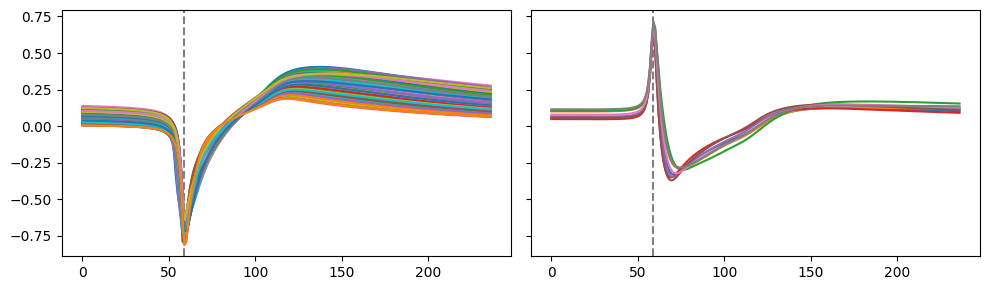

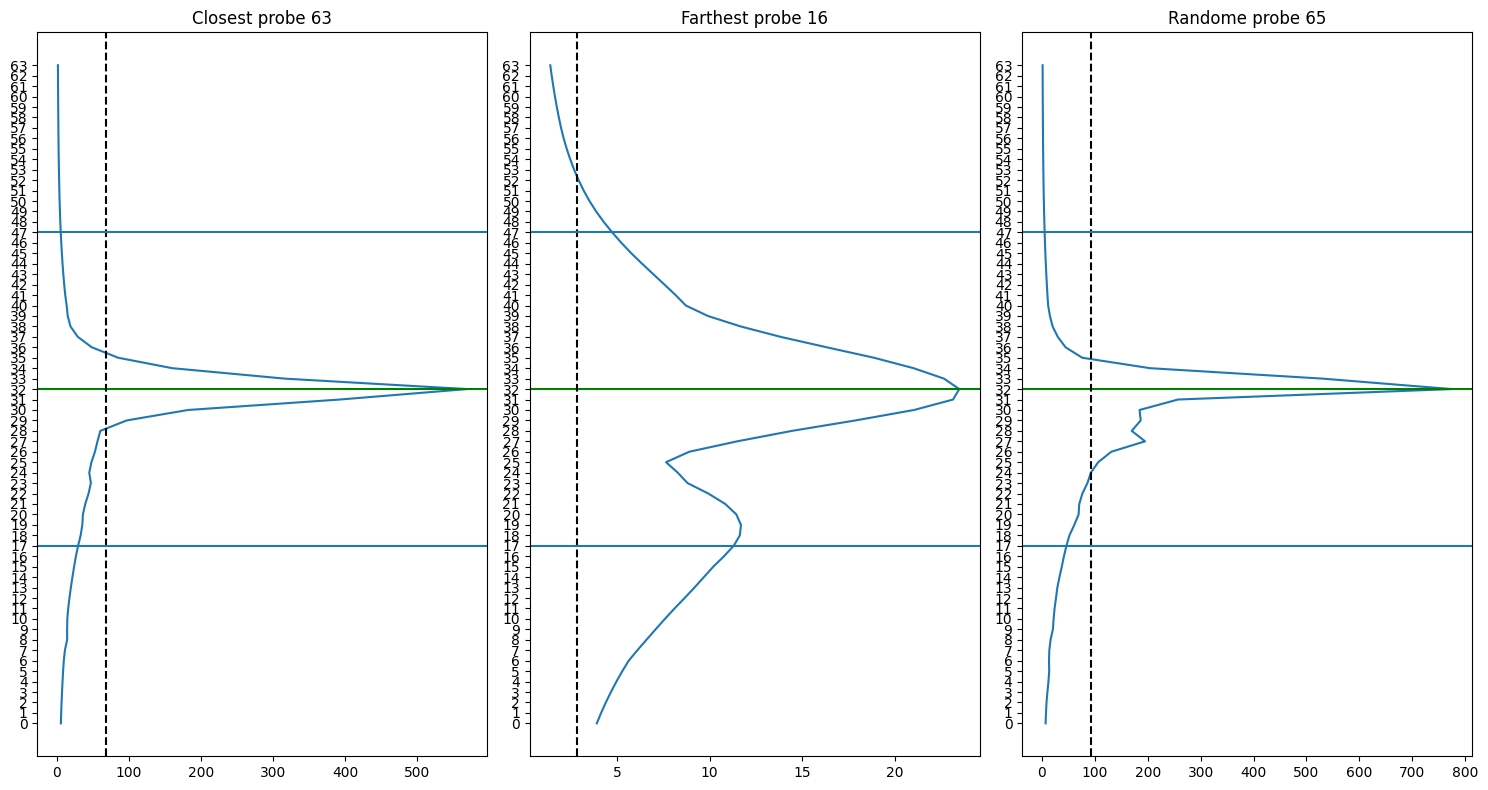

In [4]:
n_probes = 100
n_channels = 64
sim_name = 'INJ_soma'
sim_flag = 'probes_dl'

top_dir = os.path.dirname(os.path.dirname(os.getcwd()))
sim_dir = os.path.join(top_dir, f'models/NEURON/NMLCL000073-NEURON/output/{sim_name}')
# sim_label = f'{sim_name}-0nA-50Ex1-1x40Hz-{n_probes}x{n_channels}lp-{sim_flag}'  # synapses
sim_label = f'{sim_name}-1.064nA-{n_probes}x{n_channels}elec-{sim_flag}'  # current injection


eap_file_path = os.path.join(sim_dir, sim_label, f'{sim_label}-simulated_eaps.pkl')
probe_file_path = os.path.join(sim_dir, sim_label, f'{sim_label}-recording_probe_locs.pkl')

data_df = pd.read_pickle(eap_file_path)
probes = np.array(pd.read_pickle(probe_file_path))

num_probes, num_channels, _ = np.shape(probes)

probe_nums = []
channel_nums = []

for i, row in data_df.iterrows():
    probe_nums.append(int(i/num_channels))
    channel_nums.append(i%num_channels)

data_df['probe_num'] = probe_nums
data_df['channel_num'] = channel_nums

peak_threshold = 0

t = data_df.iloc[0].t
vm = data_df.iloc[0].vm
ve = data_df.iloc[0].ve

peak_time = t[np.argmin(ve)]
all_peaks = find_peaks(data_df.iloc[0].vm, threshold=peak_threshold)[0]

fig, axs = plt.subplots(1,2,figsize=(10,3),sharey=True)

offset_units = []
look_at_these = []

for probe in range(n_probes):

    probe_df = data_df[data_df['probe_num'] == probe]

    vm = probe_df.vm.iloc[0]
    t = probe_df.t.iloc[0]
    dt = t[1] - t[0]
    pre_spike_dur = 1.4
    duration = 5.6

    lb = pre_spike_dur
    ub = duration-pre_spike_dur

    all_peaks = find_peaks(vm, threshold=peak_threshold)[0]
    all_peak_times = t[all_peaks]
    for i, peak in enumerate(all_peak_times):
        if ((peak-lb) >= t[0]) and ((peak+ub) <= t[-1]):
            peak_time = peak
            peak_shift_i = all_peaks[i]
            break

    buff = 2
    start_time = peak_time - buff
    end_time = peak_time + 2*buff

    # approximate reduced timeseries condition
    t_cond = (t >= start_time) & (t < end_time)

    # find actual maximum channel
    temp_amps = []
    try:
        for _, row in probe_df.iterrows():
            wave = row.ve[t_cond]
            amp = np.max(wave) - np.min(wave)
            temp_amps.append(amp)
    except ValueError:
        raise Exception(f'ValueError: Length of Probe = {len(probe_df)} | Peak time = {peak_time}')
    
    # actual times for aligning waveform
    temp_amps = np.array(temp_amps)
    max_channel_i = np.argmax(temp_amps)

    max_channel_ve = probe_df[probe_df['channel_num']==max_channel_i].ve.iloc[0]

    # get new extracellular spike time
    peak_time_0 = peak_time
    
    min_peak = np.argmin(max_channel_ve[t_cond])
    min_peak_time = t[min_peak+peak_shift_i-int((buff/dt))]
    
    max_peak = np.argmax(max_channel_ve[t_cond])
    max_peak_time = t[max_peak+peak_shift_i-int((buff/dt))]
    
    min_diff = np.abs(peak_time_0-min_peak_time)
    max_diff = np.abs(peak_time_0-max_peak_time)

    # take whichever is more accurate
    if min_diff<max_diff:
        peak_time = min_peak_time
        peak = min_peak
        
    else:
        peak_time = max_peak_time
        peak = max_peak

    new_t_cond = (t >= peak_time - pre_spike_dur) & (t < peak_time - pre_spike_dur + duration)

    this_peak_idx = np.argwhere(t[new_t_cond] >= peak_time)[0][0]
    this_ve = max_channel_ve[new_t_cond]
    this_ve = this_ve/np.max(temp_amps)
    if this_ve[this_peak_idx]<0:
        axs[0].plot(this_ve)
    else:
        axs[1].plot(this_ve)
        
    if this_ve[20]<-0.25:       # TODO: What is this checking??
        look_at_these.append(probe)
        axs[1].plot(this_ve)
    
print('Where is spike:',this_peak_idx)
for i in range(2):
    axs[i].axvline(this_peak_idx,color='gray',linestyle='--',zorder=0)

# print('offset:',offset_units)
print('potential problems:',look_at_these)
plt.tight_layout();

closest_probe = find_n_closest_probes(probes, 1, max_channel_i=n_channels//2)
closest_probe_df = data_df[data_df.probe_num.isin(closest_probe)]

farthest_probe = find_n_farthest_probes(probes, 1, max_channel_i=n_channels//2)
farthest_probe_df = data_df[data_df.probe_num.isin(farthest_probe)]
rand_probe = np.random.choice(num_probes)
rand_probe_df = data_df[data_df.probe_num == rand_probe]

amps_close = []
amps_far = []
amps_rand = []
max_channels = []

for (_, row_close), (_, row_far), (_, row_rand) in zip(closest_probe_df.iterrows(), farthest_probe_df.iterrows(), rand_probe_df.iterrows()):

    amps_close.append(np.max(row_close.ve) - np.min(row_close.ve))
    amps_far.append(np.max(row_far.ve) - np.min(row_far.ve))
    amps_rand.append(np.max(row_rand.ve) - np.min(row_rand.ve))


fig, axs = plt.subplots(1, 3, figsize=(15,8))

for i in range(3):

    if i == 0:
        amps = amps_close
        title = f'Closest probe {closest_probe[0]}'
    elif i == 1:
        amps = amps_far
        title = f'Farthest probe {farthest_probe[0]}'
    else:
        amps = amps_rand
        title = f'Randome probe {rand_probe}'

    # axs[i].figure(figsize=(5,8))
    axs[i].plot(1e3*np.array(amps), np.arange(len(closest_probe_df)))
    axs[i].set_yticks(np.arange(len(closest_probe_df)))
    # axs[i].set_xlim((0,12))

    true_max = np.argmax(amps)
    axs[i].axhline(true_max, color='g')

    axs[i].axvline(0.12*1e3*np.max(amps), color='k', linestyle='--')

    axs[i].axhline(true_max+15)
    axs[i].axhline(true_max-15)

    axs[i].set_title(title)

    max_channels.append(true_max)
    print(true_max)

fig.tight_layout()
print(int(np.average(max_channels)))

max_channel = 32  # based on farthest and random probes
max_channels = int(np.average(max_channels))
max_channel_ve = closest_probe_df[closest_probe_df.channel_num == max_channel].ve.iloc[0]
low_channel_ve = closest_probe_df[closest_probe_df.channel_num == max_channel+15].ve.iloc[0]
t = closest_probe_df[closest_probe_df.channel_num == max_channel].t.iloc[0]

conversion_factor = 1e3
spike_duration = 5.6
start_time = peak_time - 1.6
end_time = start_time + spike_duration

t_cond = (t >= start_time) & (t < end_time)
reduced_t = t[t_cond]
reduced_max_ve = conversion_factor * max_channel_ve[t_cond]
reduced_low_ve = conversion_factor * low_channel_ve[t_cond]

T = len(reduced_t)
num_pts = 128
duration = reduced_t[-1] - reduced_t[0]
interp_t = np.linspace(0, duration, T)
cs = CubicSpline(interp_t, reduced_max_ve, axis=0)
new_time = np.linspace(0,duration,num_pts)
new_max_ve = cs(new_time)
cs = CubicSpline(interp_t,reduced_low_ve,axis=0)
new_time = np.linspace(0,duration,num_pts)
new_low_ve = cs(new_time)

closest_probes = find_n_closest_probes(probes, n_probes//2, max_channel_i=max_channel)
closest_probes_df = data_df[data_df.probe_num.isin(closest_probes)]

include_channels = [i for i in range(max_channel-15, max_channel+16)]
include_channels[0], include_channels[-1]

prep_closest_probes_df = closest_probes_df.copy()

probe_amps_closest = []

for probe_num in closest_probes:

    probe_df = closest_probes_df[closest_probes_df.probe_num == probe_num]

    prep_probe_df = preprocess_probe_data(probe_df, max_channel_i=max_channel, resample=512, conversion_factor=1e3, num_noisy_spikes=200)
    
    prep_closest_probes_df.update(prep_probe_df)

    probe_amp = []

    for _, row in prep_probe_df.iterrows():

        if row.channel_num in include_channels:

            ve = row.ve
            amp = np.max(ve) - np.min(ve)
            probe_amp.append(amp)

    probe_amps_closest.append(probe_amp)

avg_waves_close = []

for channel_num in include_channels:

    channel_df = prep_closest_probes_df[prep_closest_probes_df.channel_num == channel_num]

    waves = []

    for _, row in channel_df.iterrows():

        ve = row.ve
        amp = np.max(ve) - np.min(ve)
        norm_ve = np.divide(ve, amp)
        wave = list(norm_ve)
        waves.append(wave)


    waves = np.array(waves)
    channel_avg = np.average(waves, 0)

    avg_waves_close.append(channel_avg)

avg_waves_close = list(reversed(avg_waves_close))

max_channel_loc = np.argwhere(np.array(include_channels) == max_channel)[0][0]
max_avg_wave_close = avg_waves_close[max_channel_loc]

above_wave_close_current = avg_waves_close[max_channel_loc - 6]
center_wave_close_current = avg_waves_close[max_channel_loc]
below_wave_close_current = avg_waves_close[max_channel_loc + 6]

## Soma

Where is spike: 59
potential problems: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99]
Closest probe found at 10.196947669152301 microns...
Farthest probe found at 63.848040772425314 microns...
32
26
31
29
Closest probe found at 10.196947669152301 microns...


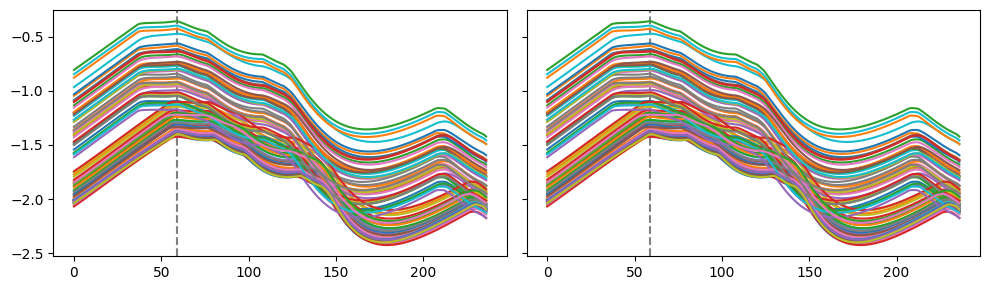

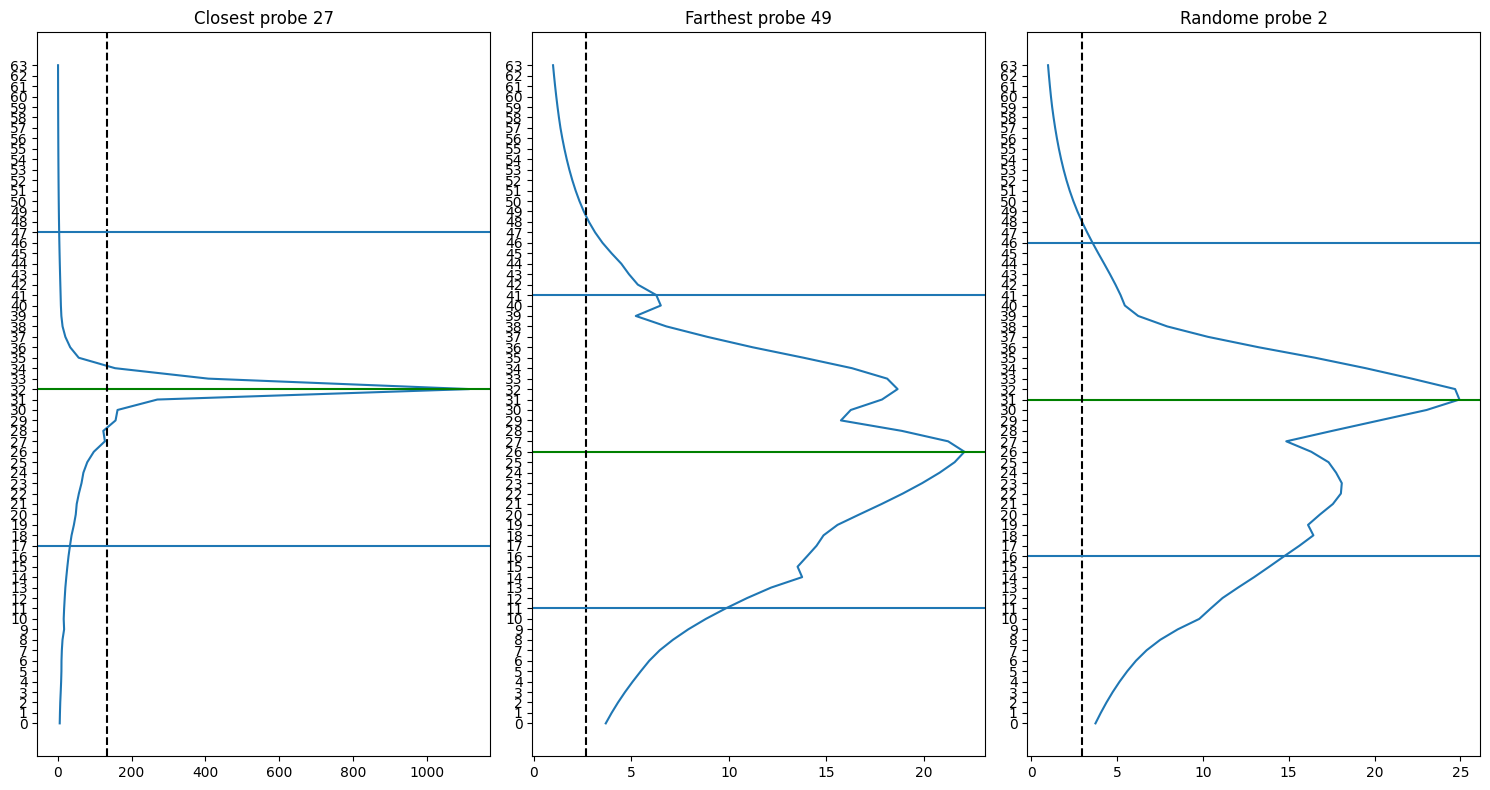

In [5]:
n_probes = 100
n_channels = 64
sim_name = 'EAP_soma'
sim_flag = 'probes_dl'
num_syns = 100

top_dir = os.path.dirname(os.path.dirname(os.getcwd()))
sim_dir = os.path.join(top_dir, f'models/NEURON/NMLCL000073-NEURON/output/{sim_name}')
# sim_label = f'{sim_name}-0nA-50Ex1-1x40Hz-{n_probes}x{n_channels}lp-{sim_flag}'  # synapses
sim_label = f'{sim_name}-0nA-{num_syns}Ex1-1x40Hz-{n_probes}x{n_channels}elec-{sim_flag}'  # current injection

eap_file_path = os.path.join(sim_dir, sim_label, f'{sim_label}-simulated_eaps.pkl')
probe_file_path = os.path.join(sim_dir, sim_label, f'{sim_label}-recording_probe_locs.pkl')

data_df = pd.read_pickle(eap_file_path)
probes = np.array(pd.read_pickle(probe_file_path))

num_probes, num_channels, _ = np.shape(probes)

probe_nums = []
channel_nums = []

for i, row in data_df.iterrows():
    probe_nums.append(int(i/num_channels))
    channel_nums.append(i%num_channels)

data_df['probe_num'] = probe_nums
data_df['channel_num'] = channel_nums

peak_threshold = 0

t = data_df.iloc[0].t
vm = data_df.iloc[0].vm
ve = data_df.iloc[0].ve

peak_time = t[np.argmin(ve)]
all_peaks = find_peaks(data_df.iloc[0].vm, threshold=peak_threshold)[0]

fig, axs = plt.subplots(1,2,figsize=(10,3),sharey=True)

offset_units = []
look_at_these = []

for probe in range(n_probes):

    probe_df = data_df[data_df['probe_num'] == probe]

    vm = probe_df.vm.iloc[0]
    t = probe_df.t.iloc[0]
    dt = t[1] - t[0]
    pre_spike_dur = 1.4
    duration = 5.6

    lb = pre_spike_dur
    ub = duration-pre_spike_dur

    all_peaks = find_peaks(vm, threshold=peak_threshold)[0]
    all_peak_times = t[all_peaks]
    for i, peak in enumerate(all_peak_times):
        if ((peak-lb) >= t[0]) and ((peak+ub) <= t[-1]):
            peak_time = peak
            peak_shift_i = all_peaks[i]
            break

    buff = 2
    start_time = peak_time - buff
    end_time = peak_time + 2*buff

    # approximate reduced timeseries condition
    t_cond = (t >= start_time) & (t < end_time)

    # find actual maximum channel
    temp_amps = []
    try:
        for _, row in probe_df.iterrows():
            wave = row.ve[t_cond]
            amp = np.max(wave) - np.min(wave)
            temp_amps.append(amp)
    except ValueError:
        raise Exception(f'ValueError: Length of Probe = {len(probe_df)} | Peak time = {peak_time}')
    
    # actual times for aligning waveform
    temp_amps = np.array(temp_amps)
    max_channel_i = np.argmax(temp_amps)

    max_channel_ve = probe_df[probe_df['channel_num']==max_channel_i].ve.iloc[0]

    # get new extracellular spike time
    peak_time_0 = peak_time
    
    min_peak = np.argmin(max_channel_ve[t_cond])
    min_peak_time = t[min_peak+peak_shift_i-int((buff/dt))]
    
    max_peak = np.argmax(max_channel_ve[t_cond])
    max_peak_time = t[max_peak+peak_shift_i-int((buff/dt))]
    
    min_diff = np.abs(peak_time_0-min_peak_time)
    max_diff = np.abs(peak_time_0-max_peak_time)

    # take whichever is more accurate
    if min_diff<max_diff:
        peak_time = min_peak_time
        peak = min_peak
        
    else:
        peak_time = max_peak_time
        peak = max_peak

    new_t_cond = (t >= peak_time - pre_spike_dur) & (t < peak_time - pre_spike_dur + duration)

    this_peak_idx = np.argwhere(t[new_t_cond] >= peak_time)[0][0]
    this_ve = max_channel_ve[new_t_cond]
    this_ve = this_ve/np.max(temp_amps)
    if this_ve[this_peak_idx]<0:
        axs[0].plot(this_ve)
    else:
        axs[1].plot(this_ve)
        
    if this_ve[20]<-0.25:       # TODO: What is this checking??
        look_at_these.append(probe)
        axs[1].plot(this_ve)
    
print('Where is spike:',this_peak_idx)
for i in range(2):
    axs[i].axvline(this_peak_idx,color='gray',linestyle='--',zorder=0)

# print('offset:',offset_units)
print('potential problems:',look_at_these)
plt.tight_layout();

closest_probe = find_n_closest_probes(probes, 1, max_channel_i=n_channels//2)
closest_probe_df = data_df[data_df.probe_num.isin(closest_probe)]

farthest_probe = find_n_farthest_probes(probes, 1, max_channel_i=n_channels//2)
farthest_probe_df = data_df[data_df.probe_num.isin(farthest_probe)]
rand_probe = np.random.choice(num_probes)
rand_probe_df = data_df[data_df.probe_num == rand_probe]

amps_close = []
amps_far = []
amps_rand = []
max_channels = []

for (_, row_close), (_, row_far), (_, row_rand) in zip(closest_probe_df.iterrows(), farthest_probe_df.iterrows(), rand_probe_df.iterrows()):

    amps_close.append(np.max(row_close.ve) - np.min(row_close.ve))
    amps_far.append(np.max(row_far.ve) - np.min(row_far.ve))
    amps_rand.append(np.max(row_rand.ve) - np.min(row_rand.ve))


fig, axs = plt.subplots(1, 3, figsize=(15,8))

for i in range(3):

    if i == 0:
        amps = amps_close
        title = f'Closest probe {closest_probe[0]}'
    elif i == 1:
        amps = amps_far
        title = f'Farthest probe {farthest_probe[0]}'
    else:
        amps = amps_rand
        title = f'Randome probe {rand_probe}'

    # axs[i].figure(figsize=(5,8))
    axs[i].plot(1e3*np.array(amps), np.arange(len(closest_probe_df)))
    axs[i].set_yticks(np.arange(len(closest_probe_df)))
    # axs[i].set_xlim((0,12))

    true_max = np.argmax(amps)
    axs[i].axhline(true_max, color='g')

    axs[i].axvline(0.12*1e3*np.max(amps), color='k', linestyle='--')

    axs[i].axhline(true_max+15)
    axs[i].axhline(true_max-15)

    axs[i].set_title(title)

    max_channels.append(true_max)
    print(true_max)

fig.tight_layout()
print(int(np.average(max_channels)))

max_channel = 32  # based on farthest and random probes
max_channels = int(np.average(max_channels))
max_channel_ve = closest_probe_df[closest_probe_df.channel_num == max_channel].ve.iloc[0]
low_channel_ve = closest_probe_df[closest_probe_df.channel_num == max_channel+15].ve.iloc[0]
t = closest_probe_df[closest_probe_df.channel_num == max_channel].t.iloc[0]

conversion_factor = 1e3
spike_duration = 5.6
start_time = peak_time - 1.6
end_time = start_time + spike_duration

t_cond = (t >= start_time) & (t < end_time)
reduced_t = t[t_cond]
reduced_max_ve = conversion_factor * max_channel_ve[t_cond]
reduced_low_ve = conversion_factor * low_channel_ve[t_cond]

T = len(reduced_t)
num_pts = 128
duration = reduced_t[-1] - reduced_t[0]
interp_t = np.linspace(0, duration, T)
cs = CubicSpline(interp_t, reduced_max_ve, axis=0)
new_time = np.linspace(0,duration,num_pts)
new_max_ve = cs(new_time)
cs = CubicSpline(interp_t,reduced_low_ve,axis=0)
new_time = np.linspace(0,duration,num_pts)
new_low_ve = cs(new_time)

closest_probes = find_n_closest_probes(probes, n_probes//2, max_channel_i=max_channel)
closest_probes_df = data_df[data_df.probe_num.isin(closest_probes)]

include_channels = [i for i in range(max_channel-15, max_channel+16)]
include_channels[0], include_channels[-1]

prep_closest_probes_df = closest_probes_df.copy()

probe_amps_closest = []

for probe_num in closest_probes:

    probe_df = closest_probes_df[closest_probes_df.probe_num == probe_num]

    prep_probe_df = preprocess_probe_data(probe_df, max_channel_i=max_channel, resample=512, conversion_factor=1e3, num_noisy_spikes=200)
    
    prep_closest_probes_df.update(prep_probe_df)

    probe_amp = []

    for _, row in prep_probe_df.iterrows():

        if row.channel_num in include_channels:

            ve = row.ve
            amp = np.max(ve) - np.min(ve)
            probe_amp.append(amp)

    probe_amps_closest.append(probe_amp)

avg_waves_close = []

for channel_num in include_channels:

    channel_df = prep_closest_probes_df[prep_closest_probes_df.channel_num == channel_num]

    waves = []

    for _, row in channel_df.iterrows():

        ve = row.ve
        amp = np.max(ve) - np.min(ve)
        norm_ve = np.divide(ve, amp)
        wave = list(norm_ve)
        waves.append(wave)


    waves = np.array(waves)
    channel_avg = np.average(waves, 0)

    avg_waves_close.append(channel_avg)

avg_waves_close = list(reversed(avg_waves_close))

max_channel_loc = np.argwhere(np.array(include_channels) == max_channel)[0][0]
max_avg_wave_close = avg_waves_close[max_channel_loc]

above_wave_close_soma = avg_waves_close[max_channel_loc - 6]
center_wave_close_soma = avg_waves_close[max_channel_loc]
below_wave_close_soma = avg_waves_close[max_channel_loc + 6]

## Basal

Where is spike: 59
potential problems: []
Closest probe found at 11.42361131728794 microns...
Farthest probe found at 64.78185418464409 microns...
32
32
33
32
Closest probe found at 11.42361131728794 microns...


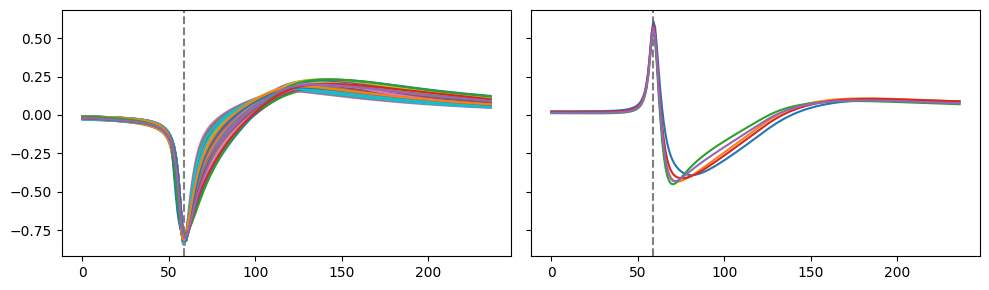

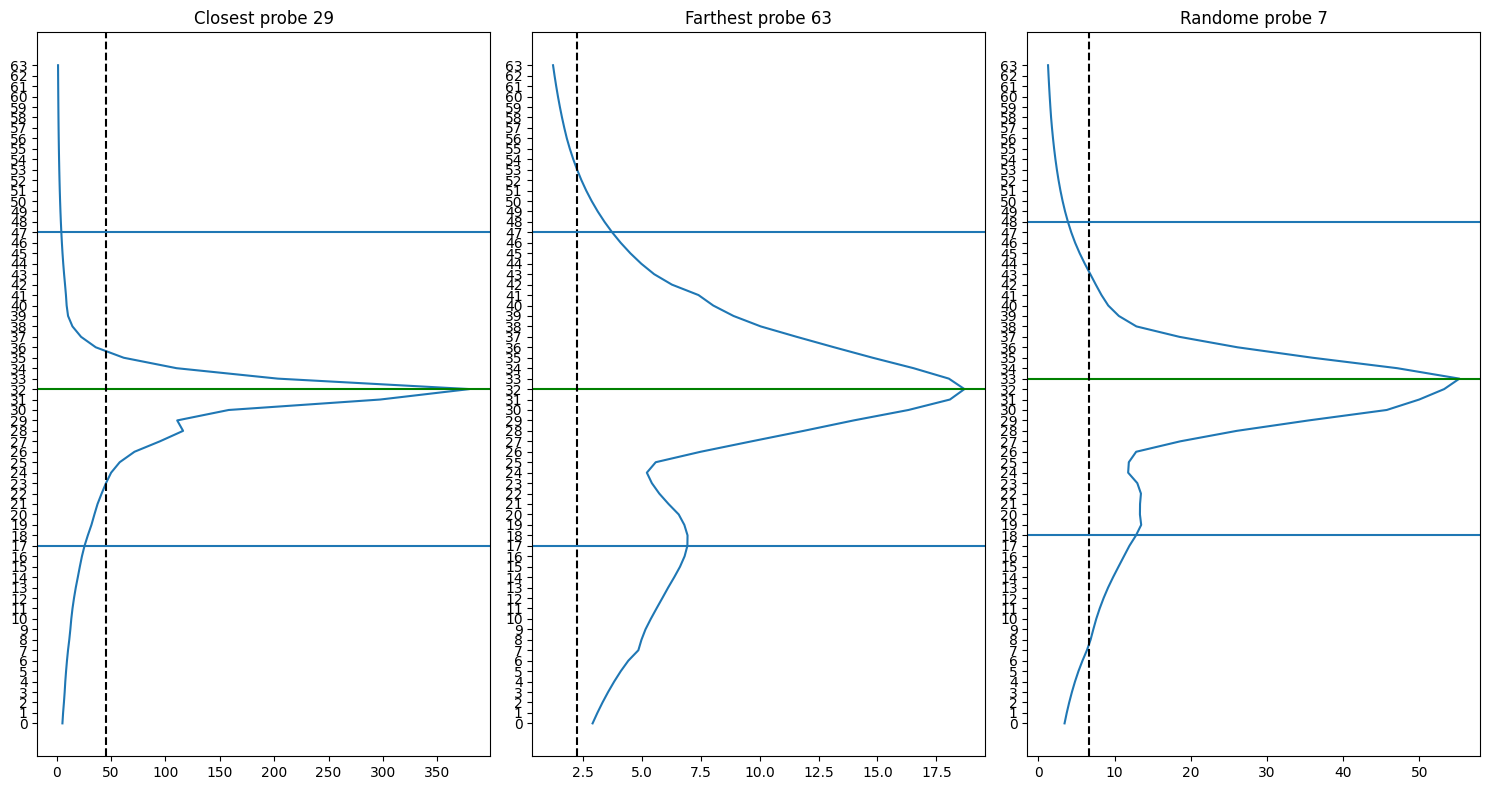

In [6]:
n_probes = 100
n_channels = 64
sim_name = 'EAP_basal'
sim_flag = 'probes_dl'
num_syns = 100

top_dir = os.path.dirname(os.path.dirname(os.getcwd()))
sim_dir = os.path.join(top_dir, f'models/NEURON/NMLCL000073-NEURON/output/{sim_name}')
# sim_label = f'{sim_name}-0nA-50Ex1-1x40Hz-{n_probes}x{n_channels}lp-{sim_flag}'  # synapses
sim_label = f'{sim_name}-0nA-{num_syns}Ex1-1x40Hz-{n_probes}x{n_channels}elec-{sim_flag}'  # current injection

eap_file_path = os.path.join(sim_dir, sim_label, f'{sim_label}-simulated_eaps.pkl')
probe_file_path = os.path.join(sim_dir, sim_label, f'{sim_label}-recording_probe_locs.pkl')

data_df = pd.read_pickle(eap_file_path)
probes = np.array(pd.read_pickle(probe_file_path))

num_probes, num_channels, _ = np.shape(probes)

probe_nums = []
channel_nums = []

for i, row in data_df.iterrows():
    probe_nums.append(int(i/num_channels))
    channel_nums.append(i%num_channels)

data_df['probe_num'] = probe_nums
data_df['channel_num'] = channel_nums

peak_threshold = 0

t = data_df.iloc[0].t
vm = data_df.iloc[0].vm
ve = data_df.iloc[0].ve

peak_time = t[np.argmin(ve)]
all_peaks = find_peaks(data_df.iloc[0].vm, threshold=peak_threshold)[0]

fig, axs = plt.subplots(1,2,figsize=(10,3),sharey=True)

offset_units = []
look_at_these = []

for probe in range(n_probes):

    probe_df = data_df[data_df['probe_num'] == probe]

    vm = probe_df.vm.iloc[0]
    t = probe_df.t.iloc[0]
    dt = t[1] - t[0]
    pre_spike_dur = 1.4
    duration = 5.6

    lb = pre_spike_dur
    ub = duration-pre_spike_dur

    all_peaks = find_peaks(vm, threshold=peak_threshold)[0]
    all_peak_times = t[all_peaks]
    for i, peak in enumerate(all_peak_times):
        if ((peak-lb) >= t[0]) and ((peak+ub) <= t[-1]):
            peak_time = peak
            peak_shift_i = all_peaks[i]
            break

    buff = 2
    start_time = peak_time - buff
    end_time = peak_time + 2*buff

    # approximate reduced timeseries condition
    t_cond = (t >= start_time) & (t < end_time)

    # find actual maximum channel
    temp_amps = []
    try:
        for _, row in probe_df.iterrows():
            wave = row.ve[t_cond]
            amp = np.max(wave) - np.min(wave)
            temp_amps.append(amp)
    except ValueError:
        raise Exception(f'ValueError: Length of Probe = {len(probe_df)} | Peak time = {peak_time}')
    
    # actual times for aligning waveform
    temp_amps = np.array(temp_amps)
    max_channel_i = np.argmax(temp_amps)

    max_channel_ve = probe_df[probe_df['channel_num']==max_channel_i].ve.iloc[0]

    # get new extracellular spike time
    peak_time_0 = peak_time
    
    min_peak = np.argmin(max_channel_ve[t_cond])
    min_peak_time = t[min_peak+peak_shift_i-int((buff/dt))]
    
    max_peak = np.argmax(max_channel_ve[t_cond])
    max_peak_time = t[max_peak+peak_shift_i-int((buff/dt))]
    
    min_diff = np.abs(peak_time_0-min_peak_time)
    max_diff = np.abs(peak_time_0-max_peak_time)

    # take whichever is more accurate
    if min_diff<max_diff:
        peak_time = min_peak_time
        peak = min_peak
        
    else:
        peak_time = max_peak_time
        peak = max_peak

    new_t_cond = (t >= peak_time - pre_spike_dur) & (t < peak_time - pre_spike_dur + duration)

    this_peak_idx = np.argwhere(t[new_t_cond] >= peak_time)[0][0]
    this_ve = max_channel_ve[new_t_cond]
    this_ve = this_ve/np.max(temp_amps)
    if this_ve[this_peak_idx]<0:
        axs[0].plot(this_ve)
    else:
        axs[1].plot(this_ve)
        
    if this_ve[20]<-0.25:       # TODO: What is this checking??
        look_at_these.append(probe)
        axs[1].plot(this_ve)
    
print('Where is spike:',this_peak_idx)
for i in range(2):
    axs[i].axvline(this_peak_idx,color='gray',linestyle='--',zorder=0)

# print('offset:',offset_units)
print('potential problems:',look_at_these)
plt.tight_layout();

closest_probe = find_n_closest_probes(probes, 1, max_channel_i=n_channels//2)
closest_probe_df = data_df[data_df.probe_num.isin(closest_probe)]

farthest_probe = find_n_farthest_probes(probes, 1, max_channel_i=n_channels//2)
farthest_probe_df = data_df[data_df.probe_num.isin(farthest_probe)]
rand_probe = np.random.choice(num_probes)
rand_probe_df = data_df[data_df.probe_num == rand_probe]

amps_close = []
amps_far = []
amps_rand = []
max_channels = []

for (_, row_close), (_, row_far), (_, row_rand) in zip(closest_probe_df.iterrows(), farthest_probe_df.iterrows(), rand_probe_df.iterrows()):

    amps_close.append(np.max(row_close.ve) - np.min(row_close.ve))
    amps_far.append(np.max(row_far.ve) - np.min(row_far.ve))
    amps_rand.append(np.max(row_rand.ve) - np.min(row_rand.ve))


fig, axs = plt.subplots(1, 3, figsize=(15,8))

for i in range(3):

    if i == 0:
        amps = amps_close
        title = f'Closest probe {closest_probe[0]}'
    elif i == 1:
        amps = amps_far
        title = f'Farthest probe {farthest_probe[0]}'
    else:
        amps = amps_rand
        title = f'Randome probe {rand_probe}'

    # axs[i].figure(figsize=(5,8))
    axs[i].plot(1e3*np.array(amps), np.arange(len(closest_probe_df)))
    axs[i].set_yticks(np.arange(len(closest_probe_df)))
    # axs[i].set_xlim((0,12))

    true_max = np.argmax(amps)
    axs[i].axhline(true_max, color='g')

    axs[i].axvline(0.12*1e3*np.max(amps), color='k', linestyle='--')

    axs[i].axhline(true_max+15)
    axs[i].axhline(true_max-15)

    axs[i].set_title(title)

    max_channels.append(true_max)
    print(true_max)

fig.tight_layout()
print(int(np.average(max_channels)))

max_channel = 32  # based on farthest and random probes
max_channels = int(np.average(max_channels))
max_channel_ve = closest_probe_df[closest_probe_df.channel_num == max_channel].ve.iloc[0]
low_channel_ve = closest_probe_df[closest_probe_df.channel_num == max_channel+15].ve.iloc[0]
t = closest_probe_df[closest_probe_df.channel_num == max_channel].t.iloc[0]

conversion_factor = 1e3
spike_duration = 5.6
start_time = peak_time - 1.6
end_time = start_time + spike_duration

t_cond = (t >= start_time) & (t < end_time)
reduced_t = t[t_cond]
reduced_max_ve = conversion_factor * max_channel_ve[t_cond]
reduced_low_ve = conversion_factor * low_channel_ve[t_cond]

T = len(reduced_t)
num_pts = 128
duration = reduced_t[-1] - reduced_t[0]
interp_t = np.linspace(0, duration, T)
cs = CubicSpline(interp_t, reduced_max_ve, axis=0)
new_time = np.linspace(0,duration,num_pts)
new_max_ve = cs(new_time)
cs = CubicSpline(interp_t,reduced_low_ve,axis=0)
new_time = np.linspace(0,duration,num_pts)
new_low_ve = cs(new_time)

closest_probes = find_n_closest_probes(probes, n_probes//2, max_channel_i=max_channel)
closest_probes_df = data_df[data_df.probe_num.isin(closest_probes)]

include_channels = [i for i in range(max_channel-15, max_channel+16)]
include_channels[0], include_channels[-1]

prep_closest_probes_df = closest_probes_df.copy()

probe_amps_closest = []

for probe_num in closest_probes:

    probe_df = closest_probes_df[closest_probes_df.probe_num == probe_num]

    prep_probe_df = preprocess_probe_data(probe_df, max_channel_i=max_channel, resample=512, conversion_factor=1e3, num_noisy_spikes=200)
    
    prep_closest_probes_df.update(prep_probe_df)

    probe_amp = []

    for _, row in prep_probe_df.iterrows():

        if row.channel_num in include_channels:

            ve = row.ve
            amp = np.max(ve) - np.min(ve)
            probe_amp.append(amp)

    probe_amps_closest.append(probe_amp)

avg_waves_close = []

for channel_num in include_channels:

    channel_df = prep_closest_probes_df[prep_closest_probes_df.channel_num == channel_num]

    waves = []

    for _, row in channel_df.iterrows():

        ve = row.ve
        amp = np.max(ve) - np.min(ve)
        norm_ve = np.divide(ve, amp)
        wave = list(norm_ve)
        waves.append(wave)


    waves = np.array(waves)
    channel_avg = np.average(waves, 0)

    avg_waves_close.append(channel_avg)

avg_waves_close = list(reversed(avg_waves_close))

max_channel_loc = np.argwhere(np.array(include_channels) == max_channel)[0][0]
max_avg_wave_close = avg_waves_close[max_channel_loc]

above_wave_close_basal = avg_waves_close[max_channel_loc - 6]
center_wave_close_basal = avg_waves_close[max_channel_loc]
below_wave_close_basal = avg_waves_close[max_channel_loc + 6]

## Distal Apical

Where is spike: 59
potential problems: []
Closest probe found at 11.520421106775828 microns...
Farthest probe found at 64.66841341948421 microns...
32
33
32
32
Closest probe found at 11.520421106775828 microns...


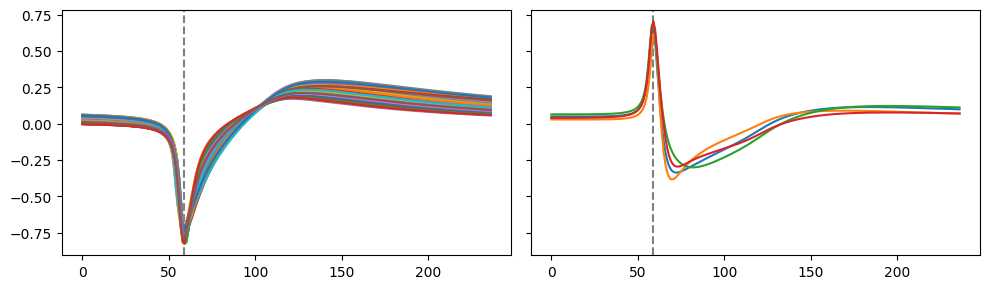

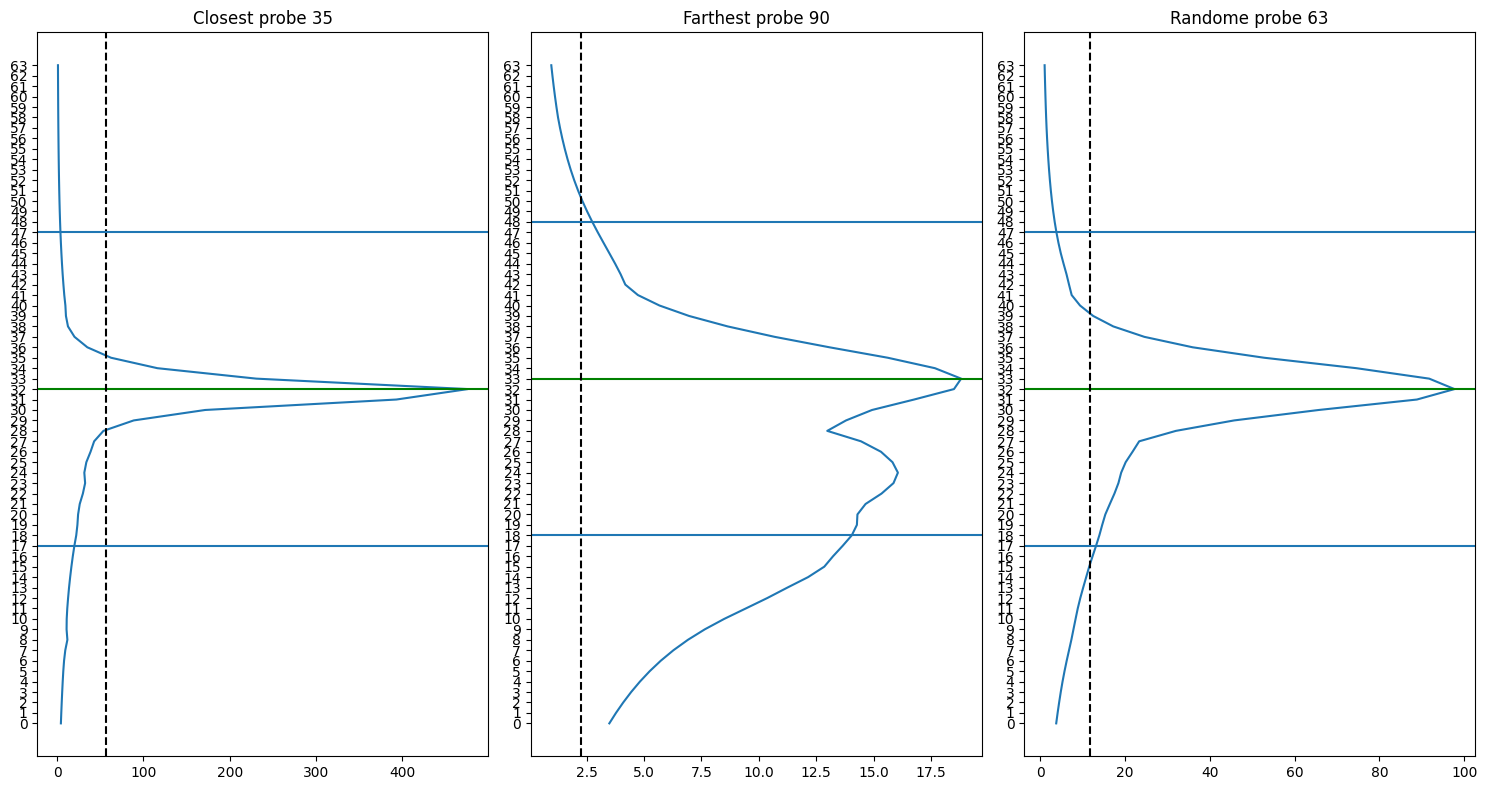

In [7]:
n_probes = 100
n_channels = 64
sim_name = 'EAP_apical_distal'
sim_flag = 'probes_dl'
num_syns = 1400

top_dir = os.path.dirname(os.path.dirname(os.getcwd()))
sim_dir = os.path.join(top_dir, f'models/NEURON/NMLCL000073-NEURON/output/{sim_name}')
# sim_label = f'{sim_name}-0nA-50Ex1-1x40Hz-{n_probes}x{n_channels}lp-{sim_flag}'  # synapses
sim_label = f'{sim_name}-0nA-{num_syns}Ex1-1x40Hz-{n_probes}x{n_channels}elec-{sim_flag}'  # current injection

eap_file_path = os.path.join(sim_dir, sim_label, f'{sim_label}-simulated_eaps.pkl')
probe_file_path = os.path.join(sim_dir, sim_label, f'{sim_label}-recording_probe_locs.pkl')

data_df = pd.read_pickle(eap_file_path)
probes = np.array(pd.read_pickle(probe_file_path))

num_probes, num_channels, _ = np.shape(probes)

probe_nums = []
channel_nums = []

for i, row in data_df.iterrows():
    probe_nums.append(int(i/num_channels))
    channel_nums.append(i%num_channels)

data_df['probe_num'] = probe_nums
data_df['channel_num'] = channel_nums

peak_threshold = 0

t = data_df.iloc[0].t
vm = data_df.iloc[0].vm
ve = data_df.iloc[0].ve

peak_time = t[np.argmin(ve)]
all_peaks = find_peaks(data_df.iloc[0].vm, threshold=peak_threshold)[0]

fig, axs = plt.subplots(1,2,figsize=(10,3),sharey=True)

offset_units = []
look_at_these = []

for probe in range(n_probes):

    probe_df = data_df[data_df['probe_num'] == probe]

    vm = probe_df.vm.iloc[0]
    t = probe_df.t.iloc[0]
    dt = t[1] - t[0]
    pre_spike_dur = 1.4
    duration = 5.6

    lb = pre_spike_dur
    ub = duration-pre_spike_dur

    all_peaks = find_peaks(vm, threshold=peak_threshold)[0]
    all_peak_times = t[all_peaks]
    for i, peak in enumerate(all_peak_times):
        if ((peak-lb) >= t[0]) and ((peak+ub) <= t[-1]):
            peak_time = peak
            peak_shift_i = all_peaks[i]
            break

    buff = 2
    start_time = peak_time - buff
    end_time = peak_time + 2*buff

    # approximate reduced timeseries condition
    t_cond = (t >= start_time) & (t < end_time)

    # find actual maximum channel
    temp_amps = []
    try:
        for _, row in probe_df.iterrows():
            wave = row.ve[t_cond]
            amp = np.max(wave) - np.min(wave)
            temp_amps.append(amp)
    except ValueError:
        raise Exception(f'ValueError: Length of Probe = {len(probe_df)} | Peak time = {peak_time}')
    
    # actual times for aligning waveform
    temp_amps = np.array(temp_amps)
    max_channel_i = np.argmax(temp_amps)

    max_channel_ve = probe_df[probe_df['channel_num']==max_channel_i].ve.iloc[0]

    # get new extracellular spike time
    peak_time_0 = peak_time
    
    min_peak = np.argmin(max_channel_ve[t_cond])
    min_peak_time = t[min_peak+peak_shift_i-int((buff/dt))]
    
    max_peak = np.argmax(max_channel_ve[t_cond])
    max_peak_time = t[max_peak+peak_shift_i-int((buff/dt))]
    
    min_diff = np.abs(peak_time_0-min_peak_time)
    max_diff = np.abs(peak_time_0-max_peak_time)

    # take whichever is more accurate
    if min_diff<max_diff:
        peak_time = min_peak_time
        peak = min_peak
        
    else:
        peak_time = max_peak_time
        peak = max_peak

    new_t_cond = (t >= peak_time - pre_spike_dur) & (t < peak_time - pre_spike_dur + duration)

    this_peak_idx = np.argwhere(t[new_t_cond] >= peak_time)[0][0]
    this_ve = max_channel_ve[new_t_cond]
    this_ve = this_ve/np.max(temp_amps)
    if this_ve[this_peak_idx]<0:
        axs[0].plot(this_ve)
    else:
        axs[1].plot(this_ve)
        
    if this_ve[20]<-0.25:       # TODO: What is this checking??
        look_at_these.append(probe)
        axs[1].plot(this_ve)
    
print('Where is spike:',this_peak_idx)
for i in range(2):
    axs[i].axvline(this_peak_idx,color='gray',linestyle='--',zorder=0)

# print('offset:',offset_units)
print('potential problems:',look_at_these)
plt.tight_layout();

closest_probe = find_n_closest_probes(probes, 1, max_channel_i=n_channels//2)
closest_probe_df = data_df[data_df.probe_num.isin(closest_probe)]

farthest_probe = find_n_farthest_probes(probes, 1, max_channel_i=n_channels//2)
farthest_probe_df = data_df[data_df.probe_num.isin(farthest_probe)]
rand_probe = np.random.choice(num_probes)
rand_probe_df = data_df[data_df.probe_num == rand_probe]

amps_close = []
amps_far = []
amps_rand = []
max_channels = []

for (_, row_close), (_, row_far), (_, row_rand) in zip(closest_probe_df.iterrows(), farthest_probe_df.iterrows(), rand_probe_df.iterrows()):

    amps_close.append(np.max(row_close.ve) - np.min(row_close.ve))
    amps_far.append(np.max(row_far.ve) - np.min(row_far.ve))
    amps_rand.append(np.max(row_rand.ve) - np.min(row_rand.ve))


fig, axs = plt.subplots(1, 3, figsize=(15,8))

for i in range(3):

    if i == 0:
        amps = amps_close
        title = f'Closest probe {closest_probe[0]}'
    elif i == 1:
        amps = amps_far
        title = f'Farthest probe {farthest_probe[0]}'
    else:
        amps = amps_rand
        title = f'Randome probe {rand_probe}'

    # axs[i].figure(figsize=(5,8))
    axs[i].plot(1e3*np.array(amps), np.arange(len(closest_probe_df)))
    axs[i].set_yticks(np.arange(len(closest_probe_df)))
    # axs[i].set_xlim((0,12))

    true_max = np.argmax(amps)
    axs[i].axhline(true_max, color='g')

    axs[i].axvline(0.12*1e3*np.max(amps), color='k', linestyle='--')

    axs[i].axhline(true_max+15)
    axs[i].axhline(true_max-15)

    axs[i].set_title(title)

    max_channels.append(true_max)
    print(true_max)

fig.tight_layout()
print(int(np.average(max_channels)))

max_channel = 32  # based on farthest and random probes
max_channels = int(np.average(max_channels))
max_channel_ve = closest_probe_df[closest_probe_df.channel_num == max_channel].ve.iloc[0]
low_channel_ve = closest_probe_df[closest_probe_df.channel_num == max_channel+15].ve.iloc[0]
t = closest_probe_df[closest_probe_df.channel_num == max_channel].t.iloc[0]

conversion_factor = 1e3
spike_duration = 5.6
start_time = peak_time - 1.6
end_time = start_time + spike_duration

t_cond = (t >= start_time) & (t < end_time)
reduced_t = t[t_cond]
reduced_max_ve = conversion_factor * max_channel_ve[t_cond]
reduced_low_ve = conversion_factor * low_channel_ve[t_cond]

T = len(reduced_t)
num_pts = 128
duration = reduced_t[-1] - reduced_t[0]
interp_t = np.linspace(0, duration, T)
cs = CubicSpline(interp_t, reduced_max_ve, axis=0)
new_time = np.linspace(0,duration,num_pts)
new_max_ve = cs(new_time)
cs = CubicSpline(interp_t,reduced_low_ve,axis=0)
new_time = np.linspace(0,duration,num_pts)
new_low_ve = cs(new_time)

closest_probes = find_n_closest_probes(probes, n_probes//2, max_channel_i=max_channel)
closest_probes_df = data_df[data_df.probe_num.isin(closest_probes)]

include_channels = [i for i in range(max_channel-15, max_channel+16)]
include_channels[0], include_channels[-1]

prep_closest_probes_df = closest_probes_df.copy()

probe_amps_closest = []

for probe_num in closest_probes:

    probe_df = closest_probes_df[closest_probes_df.probe_num == probe_num]

    prep_probe_df = preprocess_probe_data(probe_df, max_channel_i=max_channel, resample=512, conversion_factor=1e3, num_noisy_spikes=200)
    
    prep_closest_probes_df.update(prep_probe_df)

    probe_amp = []

    for _, row in prep_probe_df.iterrows():

        if row.channel_num in include_channels:

            ve = row.ve
            amp = np.max(ve) - np.min(ve)
            probe_amp.append(amp)

    probe_amps_closest.append(probe_amp)

avg_waves_close = []

for channel_num in include_channels:

    channel_df = prep_closest_probes_df[prep_closest_probes_df.channel_num == channel_num]

    waves = []

    for _, row in channel_df.iterrows():

        ve = row.ve
        amp = np.max(ve) - np.min(ve)
        norm_ve = np.divide(ve, amp)
        wave = list(norm_ve)
        waves.append(wave)


    waves = np.array(waves)
    channel_avg = np.average(waves, 0)

    avg_waves_close.append(channel_avg)

avg_waves_close = list(reversed(avg_waves_close))

max_channel_loc = np.argwhere(np.array(include_channels) == max_channel)[0][0]
max_avg_wave_close = avg_waves_close[max_channel_loc]

above_wave_close_apical = avg_waves_close[max_channel_loc - 6]
center_wave_close_apical = avg_waves_close[max_channel_loc]
below_wave_close_apical = avg_waves_close[max_channel_loc + 6]

## Combine

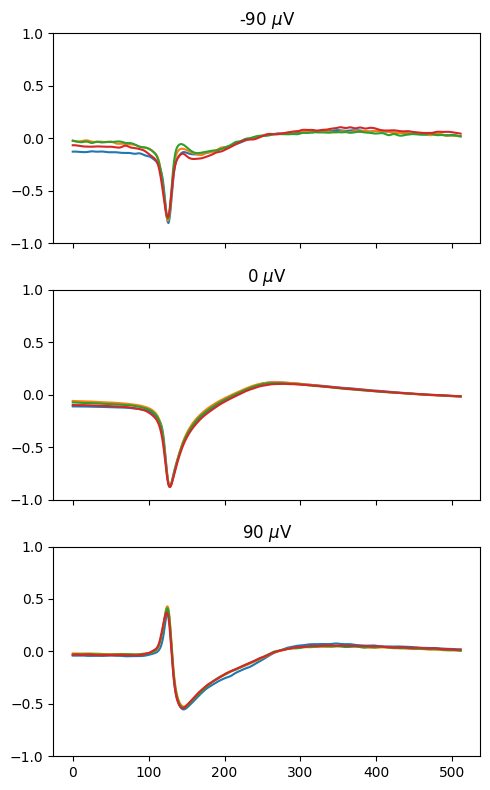

In [9]:
fig, axs = plt.subplots(3,1,figsize=(5,8), sharey=True, sharex=True)
axs = axs.ravel()

axs[0].plot(above_wave_close_current)
axs[0].plot(above_wave_close_soma)
axs[0].plot(above_wave_close_basal)
axs[0].plot(above_wave_close_apical)
axs[0].set_title(r'-90 $\mu$V')

axs[1].plot(center_wave_close_current)
axs[1].plot(center_wave_close_soma)
axs[1].plot(center_wave_close_basal)
axs[1].plot(center_wave_close_apical)
axs[1].set_title(r'0 $\mu$V')

axs[2].plot(below_wave_close_current)
axs[2].plot(below_wave_close_soma)
axs[2].plot(below_wave_close_basal)
axs[2].plot(below_wave_close_apical)
axs[2].set_title(r'90 $\mu$V')

for ax in axs:
    ax.set_ylim([-1,1])

fig.tight_layout()

# Farthest

## Current

Where is spike: 59
potential problems: []
Closest probe found at 11.061161812539977 microns...
Farthest probe found at 64.76319183721017 microns...
32
32
32
32
Farthest probe found at 64.76319183721017 microns...


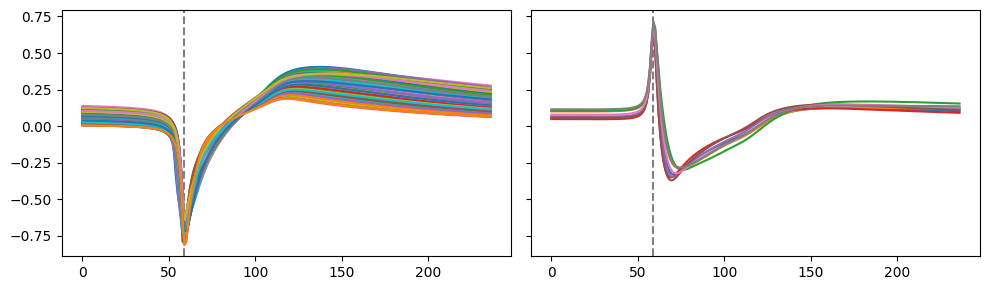

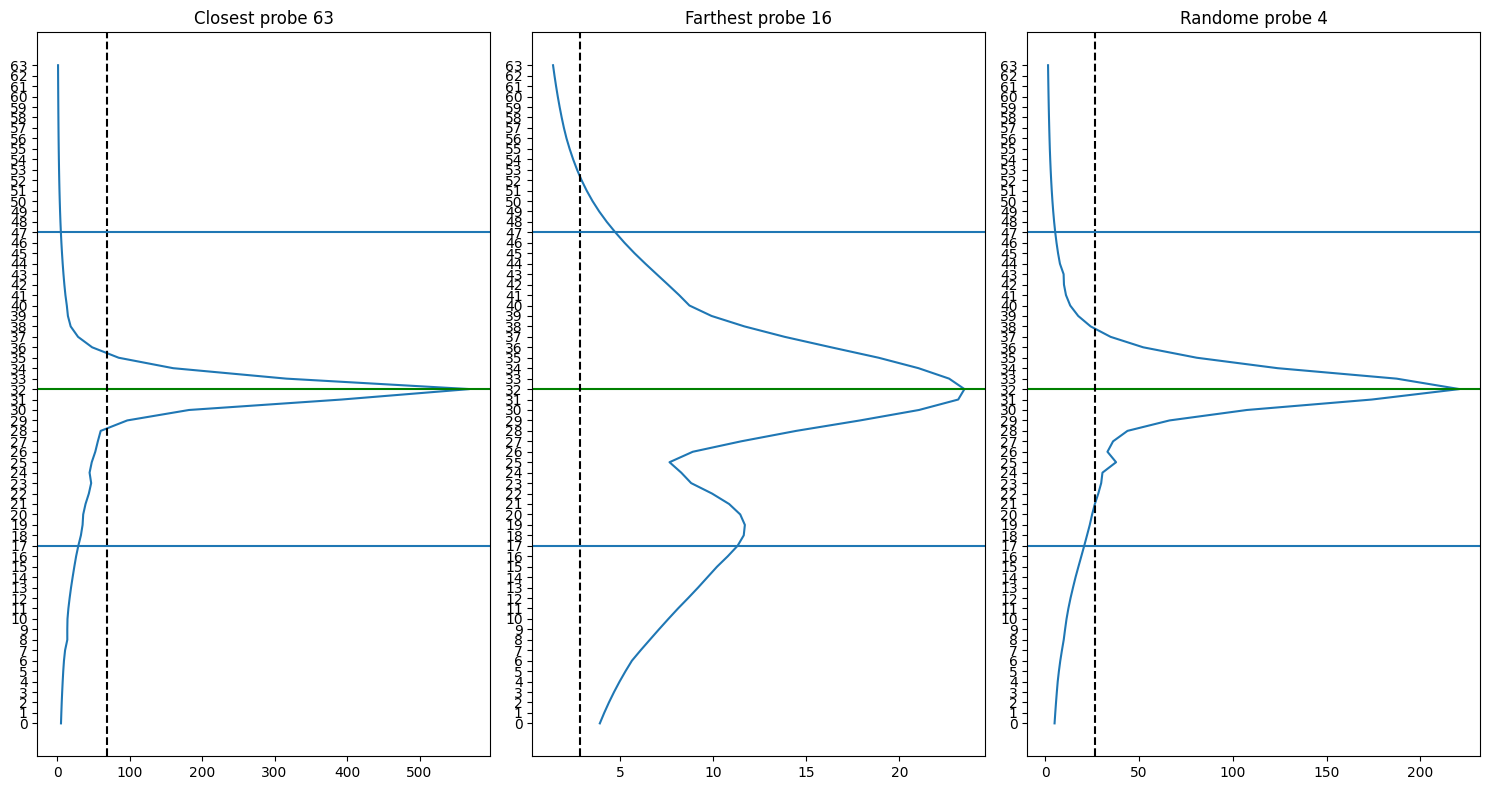

In [10]:
n_probes = 100
n_channels = 64
sim_name = 'INJ_soma'
sim_flag = 'probes_dl'

top_dir = os.path.dirname(os.path.dirname(os.getcwd()))
sim_dir = os.path.join(top_dir, f'models/NEURON/NMLCL000073-NEURON/output/{sim_name}')
# sim_label = f'{sim_name}-0nA-50Ex1-1x40Hz-{n_probes}x{n_channels}lp-{sim_flag}'  # synapses
sim_label = f'{sim_name}-1.064nA-{n_probes}x{n_channels}elec-{sim_flag}'  # current injection


eap_file_path = os.path.join(sim_dir, sim_label, f'{sim_label}-simulated_eaps.pkl')
probe_file_path = os.path.join(sim_dir, sim_label, f'{sim_label}-recording_probe_locs.pkl')

data_df = pd.read_pickle(eap_file_path)
probes = np.array(pd.read_pickle(probe_file_path))

num_probes, num_channels, _ = np.shape(probes)

probe_nums = []
channel_nums = []

for i, row in data_df.iterrows():
    probe_nums.append(int(i/num_channels))
    channel_nums.append(i%num_channels)

data_df['probe_num'] = probe_nums
data_df['channel_num'] = channel_nums

peak_threshold = 0

t = data_df.iloc[0].t
vm = data_df.iloc[0].vm
ve = data_df.iloc[0].ve

peak_time = t[np.argmin(ve)]
all_peaks = find_peaks(data_df.iloc[0].vm, threshold=peak_threshold)[0]

fig, axs = plt.subplots(1,2,figsize=(10,3),sharey=True)

offset_units = []
look_at_these = []

for probe in range(n_probes):

    probe_df = data_df[data_df['probe_num'] == probe]

    vm = probe_df.vm.iloc[0]
    t = probe_df.t.iloc[0]
    dt = t[1] - t[0]
    pre_spike_dur = 1.4
    duration = 5.6

    lb = pre_spike_dur
    ub = duration-pre_spike_dur

    all_peaks = find_peaks(vm, threshold=peak_threshold)[0]
    all_peak_times = t[all_peaks]
    for i, peak in enumerate(all_peak_times):
        if ((peak-lb) >= t[0]) and ((peak+ub) <= t[-1]):
            peak_time = peak
            peak_shift_i = all_peaks[i]
            break

    buff = 2
    start_time = peak_time - buff
    end_time = peak_time + 2*buff

    # approximate reduced timeseries condition
    t_cond = (t >= start_time) & (t < end_time)

    # find actual maximum channel
    temp_amps = []
    try:
        for _, row in probe_df.iterrows():
            wave = row.ve[t_cond]
            amp = np.max(wave) - np.min(wave)
            temp_amps.append(amp)
    except ValueError:
        raise Exception(f'ValueError: Length of Probe = {len(probe_df)} | Peak time = {peak_time}')
    
    # actual times for aligning waveform
    temp_amps = np.array(temp_amps)
    max_channel_i = np.argmax(temp_amps)

    max_channel_ve = probe_df[probe_df['channel_num']==max_channel_i].ve.iloc[0]

    # get new extracellular spike time
    peak_time_0 = peak_time
    
    min_peak = np.argmin(max_channel_ve[t_cond])
    min_peak_time = t[min_peak+peak_shift_i-int((buff/dt))]
    
    max_peak = np.argmax(max_channel_ve[t_cond])
    max_peak_time = t[max_peak+peak_shift_i-int((buff/dt))]
    
    min_diff = np.abs(peak_time_0-min_peak_time)
    max_diff = np.abs(peak_time_0-max_peak_time)

    # take whichever is more accurate
    if min_diff<max_diff:
        peak_time = min_peak_time
        peak = min_peak
        
    else:
        peak_time = max_peak_time
        peak = max_peak

    new_t_cond = (t >= peak_time - pre_spike_dur) & (t < peak_time - pre_spike_dur + duration)

    this_peak_idx = np.argwhere(t[new_t_cond] >= peak_time)[0][0]
    this_ve = max_channel_ve[new_t_cond]
    this_ve = this_ve/np.max(temp_amps)
    if this_ve[this_peak_idx]<0:
        axs[0].plot(this_ve)
    else:
        axs[1].plot(this_ve)
        
    if this_ve[20]<-0.25:       # TODO: What is this checking??
        look_at_these.append(probe)
        axs[1].plot(this_ve)
    
print('Where is spike:',this_peak_idx)
for i in range(2):
    axs[i].axvline(this_peak_idx,color='gray',linestyle='--',zorder=0)

# print('offset:',offset_units)
print('potential problems:',look_at_these)
plt.tight_layout();

closest_probe = find_n_closest_probes(probes, 1, max_channel_i=n_channels//2)
closest_probe_df = data_df[data_df.probe_num.isin(closest_probe)]

farthest_probe = find_n_farthest_probes(probes, 1, max_channel_i=n_channels//2)
farthest_probe_df = data_df[data_df.probe_num.isin(farthest_probe)]
rand_probe = np.random.choice(num_probes)
rand_probe_df = data_df[data_df.probe_num == rand_probe]

amps_close = []
amps_far = []
amps_rand = []
max_channels = []

for (_, row_close), (_, row_far), (_, row_rand) in zip(closest_probe_df.iterrows(), farthest_probe_df.iterrows(), rand_probe_df.iterrows()):

    amps_close.append(np.max(row_close.ve) - np.min(row_close.ve))
    amps_far.append(np.max(row_far.ve) - np.min(row_far.ve))
    amps_rand.append(np.max(row_rand.ve) - np.min(row_rand.ve))


fig, axs = plt.subplots(1, 3, figsize=(15,8))

for i in range(3):

    if i == 0:
        amps = amps_close
        title = f'Closest probe {closest_probe[0]}'
    elif i == 1:
        amps = amps_far
        title = f'Farthest probe {farthest_probe[0]}'
    else:
        amps = amps_rand
        title = f'Randome probe {rand_probe}'

    # axs[i].figure(figsize=(5,8))
    axs[i].plot(1e3*np.array(amps), np.arange(len(closest_probe_df)))
    axs[i].set_yticks(np.arange(len(closest_probe_df)))
    # axs[i].set_xlim((0,12))

    true_max = np.argmax(amps)
    axs[i].axhline(true_max, color='g')

    axs[i].axvline(0.12*1e3*np.max(amps), color='k', linestyle='--')

    axs[i].axhline(true_max+15)
    axs[i].axhline(true_max-15)

    axs[i].set_title(title)

    max_channels.append(true_max)
    print(true_max)

fig.tight_layout()
print(int(np.average(max_channels)))

max_channel = 32  # based on farthest and random probes
max_channels = int(np.average(max_channels))
max_channel_ve = closest_probe_df[closest_probe_df.channel_num == max_channel].ve.iloc[0]
low_channel_ve = closest_probe_df[closest_probe_df.channel_num == max_channel+15].ve.iloc[0]
t = closest_probe_df[closest_probe_df.channel_num == max_channel].t.iloc[0]

conversion_factor = 1e3
spike_duration = 5.6
start_time = peak_time - 1.6
end_time = start_time + spike_duration

t_cond = (t >= start_time) & (t < end_time)
reduced_t = t[t_cond]
reduced_max_ve = conversion_factor * max_channel_ve[t_cond]
reduced_low_ve = conversion_factor * low_channel_ve[t_cond]

T = len(reduced_t)
num_pts = 128
duration = reduced_t[-1] - reduced_t[0]
interp_t = np.linspace(0, duration, T)
cs = CubicSpline(interp_t, reduced_max_ve, axis=0)
new_time = np.linspace(0,duration,num_pts)
new_max_ve = cs(new_time)
cs = CubicSpline(interp_t,reduced_low_ve,axis=0)
new_time = np.linspace(0,duration,num_pts)
new_low_ve = cs(new_time)

farthest_probes = find_n_farthest_probes(probes, n_probes//2, max_channel_i=max_channel)
farthest_probes_df = data_df[data_df.probe_num.isin(farthest_probes)]

include_channels = [i for i in range(max_channel-15, max_channel+16)]
include_channels[0], include_channels[-1]

prep_farthest_probes_df = farthest_probes_df.copy()

probe_amps_farthest = []

for probe_num in farthest_probes:

    probe_df = farthest_probes_df[farthest_probes_df.probe_num == probe_num]

    prep_probe_df = preprocess_probe_data(probe_df, max_channel_i=max_channel, resample=512, conversion_factor=1e3, num_noisy_spikes=200)
    
    prep_farthest_probes_df.update(prep_probe_df)
    
    
    probe_amp = []

    for _, row in prep_probe_df.iterrows():

        if row.channel_num in include_channels:

            ve = row.ve
            amp = np.max(ve) - np.min(ve)
            probe_amp.append(amp)

    probe_amps_farthest.append(probe_amp)

avg_waves_far = []


for channel_num in include_channels:

    channel_df = prep_farthest_probes_df[prep_farthest_probes_df.channel_num == channel_num]

    waves = []

    for _, row in channel_df.iterrows():

        ve = row.ve
        amp = np.max(ve) - np.min(ve)
        norm_ve = np.divide(ve, amp)
        wave = list(norm_ve)
        waves.append(wave)

    waves = np.array(waves)
    channel_avg = np.average(waves, 0)

    avg_waves_far.append(channel_avg)

avg_waves_far = list(reversed(avg_waves_far))


max_channel_loc = np.argwhere(np.array(include_channels) == max_channel)[0][0]
max_avg_wave_far = avg_waves_far[max_channel_loc]

above_wave_far_current = avg_waves_far[max_channel_loc - 6]
center_wave_far_current = avg_waves_far[max_channel_loc]
below_wave_far_current = avg_waves_far[max_channel_loc + 6]

## Soma

Where is spike: 59
potential problems: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99]
Closest probe found at 10.196947669152301 microns...
Farthest probe found at 63.848040772425314 microns...
32
26
32
30
Farthest probe found at 63.848040772425314 microns...


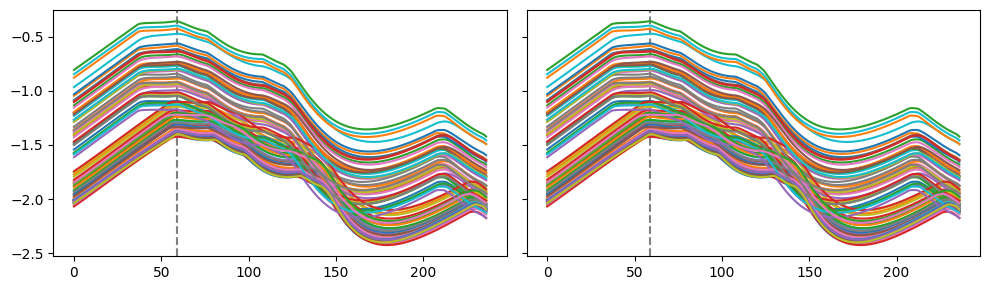

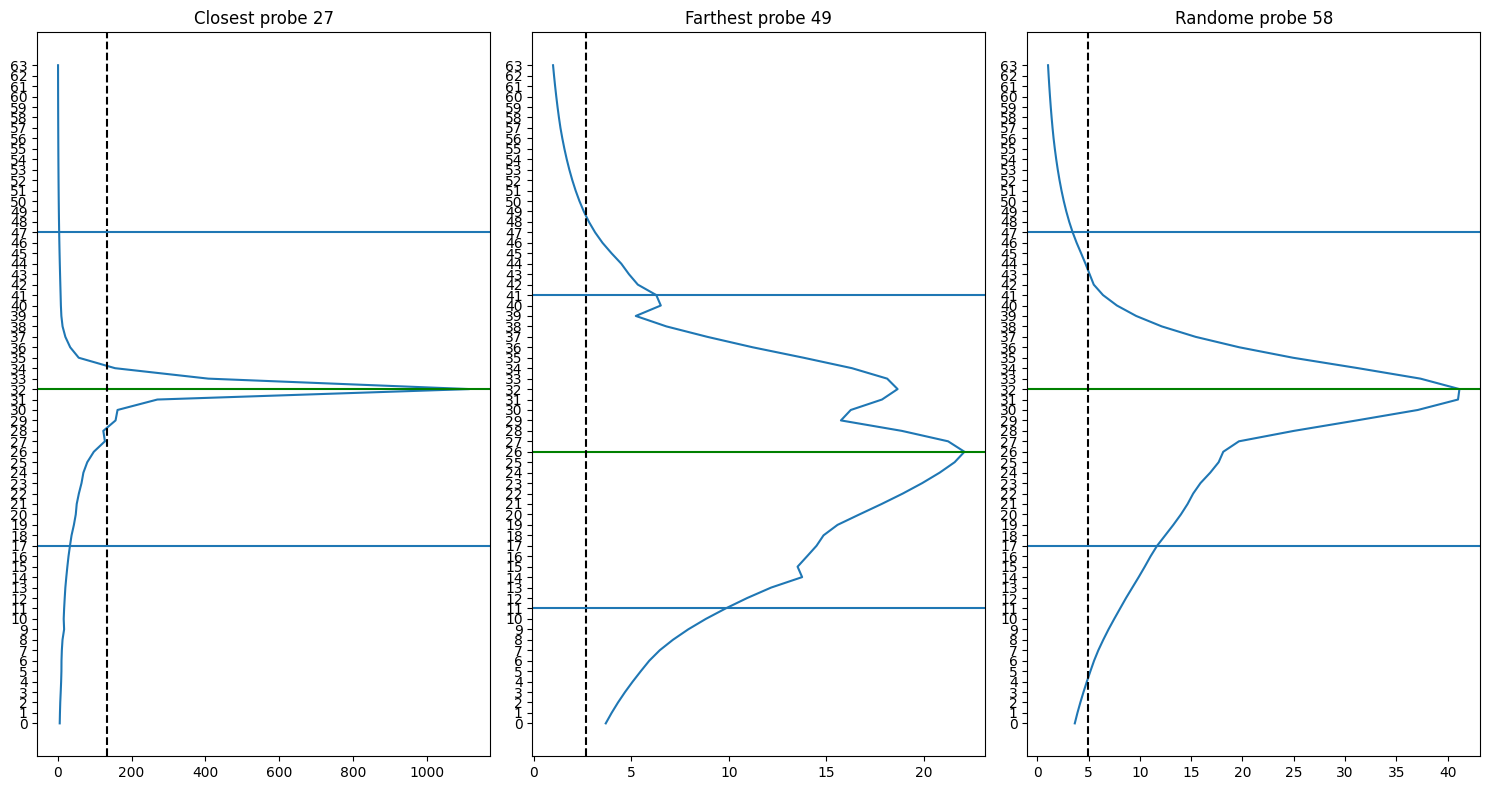

In [11]:
n_probes = 100
n_channels = 64
sim_name = 'EAP_soma'
sim_flag = 'probes_dl'
num_syns = 100

top_dir = os.path.dirname(os.path.dirname(os.getcwd()))
sim_dir = os.path.join(top_dir, f'models/NEURON/NMLCL000073-NEURON/output/{sim_name}')
# sim_label = f'{sim_name}-0nA-50Ex1-1x40Hz-{n_probes}x{n_channels}lp-{sim_flag}'  # synapses
sim_label = f'{sim_name}-0nA-{num_syns}Ex1-1x40Hz-{n_probes}x{n_channels}elec-{sim_flag}'  # current injection

eap_file_path = os.path.join(sim_dir, sim_label, f'{sim_label}-simulated_eaps.pkl')
probe_file_path = os.path.join(sim_dir, sim_label, f'{sim_label}-recording_probe_locs.pkl')

data_df = pd.read_pickle(eap_file_path)
probes = np.array(pd.read_pickle(probe_file_path))

num_probes, num_channels, _ = np.shape(probes)

probe_nums = []
channel_nums = []

for i, row in data_df.iterrows():
    probe_nums.append(int(i/num_channels))
    channel_nums.append(i%num_channels)

data_df['probe_num'] = probe_nums
data_df['channel_num'] = channel_nums

peak_threshold = 0

t = data_df.iloc[0].t
vm = data_df.iloc[0].vm
ve = data_df.iloc[0].ve

peak_time = t[np.argmin(ve)]
all_peaks = find_peaks(data_df.iloc[0].vm, threshold=peak_threshold)[0]

fig, axs = plt.subplots(1,2,figsize=(10,3),sharey=True)

offset_units = []
look_at_these = []

for probe in range(n_probes):

    probe_df = data_df[data_df['probe_num'] == probe]

    vm = probe_df.vm.iloc[0]
    t = probe_df.t.iloc[0]
    dt = t[1] - t[0]
    pre_spike_dur = 1.4
    duration = 5.6

    lb = pre_spike_dur
    ub = duration-pre_spike_dur

    all_peaks = find_peaks(vm, threshold=peak_threshold)[0]
    all_peak_times = t[all_peaks]
    for i, peak in enumerate(all_peak_times):
        if ((peak-lb) >= t[0]) and ((peak+ub) <= t[-1]):
            peak_time = peak
            peak_shift_i = all_peaks[i]
            break

    buff = 2
    start_time = peak_time - buff
    end_time = peak_time + 2*buff

    # approximate reduced timeseries condition
    t_cond = (t >= start_time) & (t < end_time)

    # find actual maximum channel
    temp_amps = []
    try:
        for _, row in probe_df.iterrows():
            wave = row.ve[t_cond]
            amp = np.max(wave) - np.min(wave)
            temp_amps.append(amp)
    except ValueError:
        raise Exception(f'ValueError: Length of Probe = {len(probe_df)} | Peak time = {peak_time}')
    
    # actual times for aligning waveform
    temp_amps = np.array(temp_amps)
    max_channel_i = np.argmax(temp_amps)

    max_channel_ve = probe_df[probe_df['channel_num']==max_channel_i].ve.iloc[0]

    # get new extracellular spike time
    peak_time_0 = peak_time
    
    min_peak = np.argmin(max_channel_ve[t_cond])
    min_peak_time = t[min_peak+peak_shift_i-int((buff/dt))]
    
    max_peak = np.argmax(max_channel_ve[t_cond])
    max_peak_time = t[max_peak+peak_shift_i-int((buff/dt))]
    
    min_diff = np.abs(peak_time_0-min_peak_time)
    max_diff = np.abs(peak_time_0-max_peak_time)

    # take whichever is more accurate
    if min_diff<max_diff:
        peak_time = min_peak_time
        peak = min_peak
        
    else:
        peak_time = max_peak_time
        peak = max_peak

    new_t_cond = (t >= peak_time - pre_spike_dur) & (t < peak_time - pre_spike_dur + duration)

    this_peak_idx = np.argwhere(t[new_t_cond] >= peak_time)[0][0]
    this_ve = max_channel_ve[new_t_cond]
    this_ve = this_ve/np.max(temp_amps)
    if this_ve[this_peak_idx]<0:
        axs[0].plot(this_ve)
    else:
        axs[1].plot(this_ve)
        
    if this_ve[20]<-0.25:       # TODO: What is this checking??
        look_at_these.append(probe)
        axs[1].plot(this_ve)
    
print('Where is spike:',this_peak_idx)
for i in range(2):
    axs[i].axvline(this_peak_idx,color='gray',linestyle='--',zorder=0)

# print('offset:',offset_units)
print('potential problems:',look_at_these)
plt.tight_layout();

closest_probe = find_n_closest_probes(probes, 1, max_channel_i=n_channels//2)
closest_probe_df = data_df[data_df.probe_num.isin(closest_probe)]

farthest_probe = find_n_farthest_probes(probes, 1, max_channel_i=n_channels//2)
farthest_probe_df = data_df[data_df.probe_num.isin(farthest_probe)]
rand_probe = np.random.choice(num_probes)
rand_probe_df = data_df[data_df.probe_num == rand_probe]

amps_close = []
amps_far = []
amps_rand = []
max_channels = []

for (_, row_close), (_, row_far), (_, row_rand) in zip(closest_probe_df.iterrows(), farthest_probe_df.iterrows(), rand_probe_df.iterrows()):

    amps_close.append(np.max(row_close.ve) - np.min(row_close.ve))
    amps_far.append(np.max(row_far.ve) - np.min(row_far.ve))
    amps_rand.append(np.max(row_rand.ve) - np.min(row_rand.ve))


fig, axs = plt.subplots(1, 3, figsize=(15,8))

for i in range(3):

    if i == 0:
        amps = amps_close
        title = f'Closest probe {closest_probe[0]}'
    elif i == 1:
        amps = amps_far
        title = f'Farthest probe {farthest_probe[0]}'
    else:
        amps = amps_rand
        title = f'Randome probe {rand_probe}'

    # axs[i].figure(figsize=(5,8))
    axs[i].plot(1e3*np.array(amps), np.arange(len(closest_probe_df)))
    axs[i].set_yticks(np.arange(len(closest_probe_df)))
    # axs[i].set_xlim((0,12))

    true_max = np.argmax(amps)
    axs[i].axhline(true_max, color='g')

    axs[i].axvline(0.12*1e3*np.max(amps), color='k', linestyle='--')

    axs[i].axhline(true_max+15)
    axs[i].axhline(true_max-15)

    axs[i].set_title(title)

    max_channels.append(true_max)
    print(true_max)

fig.tight_layout()
print(int(np.average(max_channels)))

max_channel = 32  # based on farthest and random probes
max_channels = int(np.average(max_channels))
max_channel_ve = closest_probe_df[closest_probe_df.channel_num == max_channel].ve.iloc[0]
low_channel_ve = closest_probe_df[closest_probe_df.channel_num == max_channel+15].ve.iloc[0]
t = closest_probe_df[closest_probe_df.channel_num == max_channel].t.iloc[0]

conversion_factor = 1e3
spike_duration = 5.6
start_time = peak_time - 1.6
end_time = start_time + spike_duration

t_cond = (t >= start_time) & (t < end_time)
reduced_t = t[t_cond]
reduced_max_ve = conversion_factor * max_channel_ve[t_cond]
reduced_low_ve = conversion_factor * low_channel_ve[t_cond]

T = len(reduced_t)
num_pts = 128
duration = reduced_t[-1] - reduced_t[0]
interp_t = np.linspace(0, duration, T)
cs = CubicSpline(interp_t, reduced_max_ve, axis=0)
new_time = np.linspace(0,duration,num_pts)
new_max_ve = cs(new_time)
cs = CubicSpline(interp_t,reduced_low_ve,axis=0)
new_time = np.linspace(0,duration,num_pts)
new_low_ve = cs(new_time)

farthest_probes = find_n_farthest_probes(probes, n_probes//2, max_channel_i=max_channel)
farthest_probes_df = data_df[data_df.probe_num.isin(farthest_probes)]

include_channels = [i for i in range(max_channel-15, max_channel+16)]
include_channels[0], include_channels[-1]

prep_farthest_probes_df = farthest_probes_df.copy()

probe_amps_farthest = []

for probe_num in farthest_probes:

    probe_df = farthest_probes_df[farthest_probes_df.probe_num == probe_num]

    prep_probe_df = preprocess_probe_data(probe_df, max_channel_i=max_channel, resample=512, conversion_factor=1e3, num_noisy_spikes=200)
    
    prep_farthest_probes_df.update(prep_probe_df)
    
    
    probe_amp = []

    for _, row in prep_probe_df.iterrows():

        if row.channel_num in include_channels:

            ve = row.ve
            amp = np.max(ve) - np.min(ve)
            probe_amp.append(amp)

    probe_amps_farthest.append(probe_amp)

avg_waves_far = []


for channel_num in include_channels:

    channel_df = prep_farthest_probes_df[prep_farthest_probes_df.channel_num == channel_num]

    waves = []

    for _, row in channel_df.iterrows():

        ve = row.ve
        amp = np.max(ve) - np.min(ve)
        norm_ve = np.divide(ve, amp)
        wave = list(norm_ve)
        waves.append(wave)

    waves = np.array(waves)
    channel_avg = np.average(waves, 0)

    avg_waves_far.append(channel_avg)

avg_waves_far = list(reversed(avg_waves_far))


max_channel_loc = np.argwhere(np.array(include_channels) == max_channel)[0][0]
max_avg_wave_far = avg_waves_far[max_channel_loc]

above_wave_far_soma = avg_waves_far[max_channel_loc - 6]
center_wave_far_soma = avg_waves_far[max_channel_loc]
below_wave_far_soma = avg_waves_far[max_channel_loc + 6]

## Basal

Where is spike: 59
potential problems: []
Closest probe found at 11.42361131728794 microns...
Farthest probe found at 64.78185418464409 microns...
32
32
32
32
Farthest probe found at 64.78185418464409 microns...


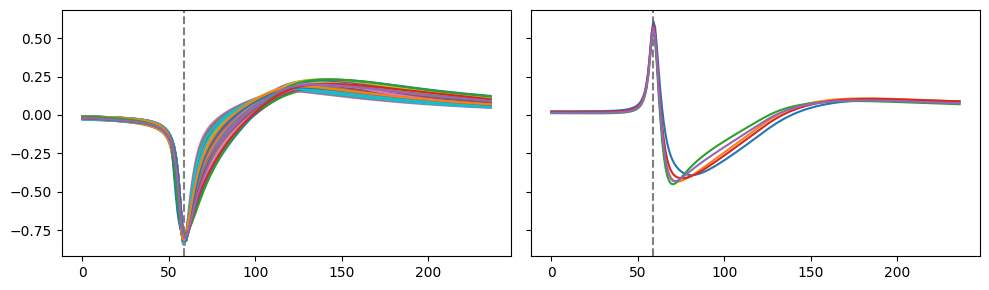

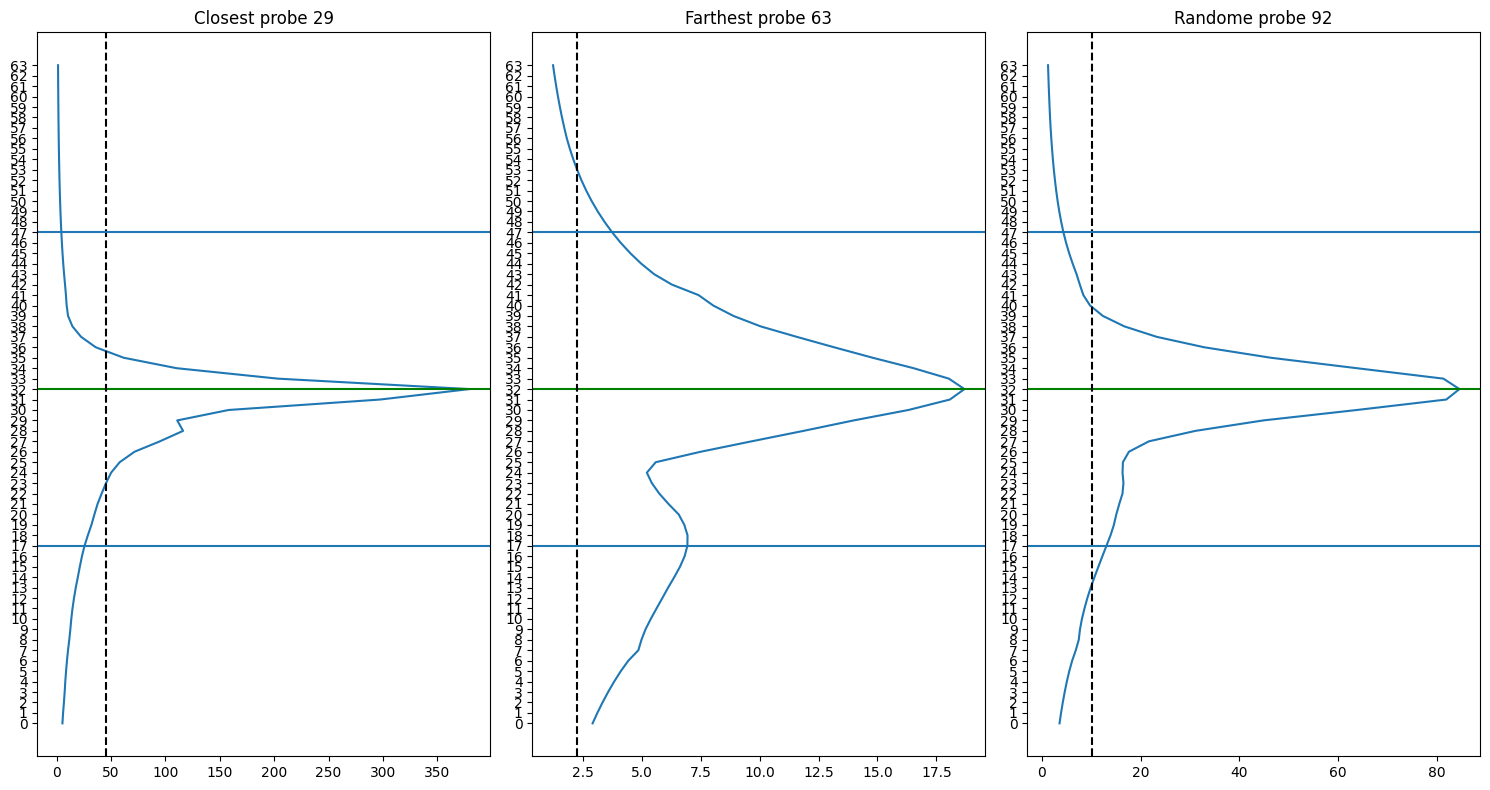

In [12]:
n_probes = 100
n_channels = 64
sim_name = 'EAP_basal'
sim_flag = 'probes_dl'
num_syns = 100

top_dir = os.path.dirname(os.path.dirname(os.getcwd()))
sim_dir = os.path.join(top_dir, f'models/NEURON/NMLCL000073-NEURON/output/{sim_name}')
# sim_label = f'{sim_name}-0nA-50Ex1-1x40Hz-{n_probes}x{n_channels}lp-{sim_flag}'  # synapses
sim_label = f'{sim_name}-0nA-{num_syns}Ex1-1x40Hz-{n_probes}x{n_channels}elec-{sim_flag}'  # current injection

eap_file_path = os.path.join(sim_dir, sim_label, f'{sim_label}-simulated_eaps.pkl')
probe_file_path = os.path.join(sim_dir, sim_label, f'{sim_label}-recording_probe_locs.pkl')

data_df = pd.read_pickle(eap_file_path)
probes = np.array(pd.read_pickle(probe_file_path))

num_probes, num_channels, _ = np.shape(probes)

probe_nums = []
channel_nums = []

for i, row in data_df.iterrows():
    probe_nums.append(int(i/num_channels))
    channel_nums.append(i%num_channels)

data_df['probe_num'] = probe_nums
data_df['channel_num'] = channel_nums

peak_threshold = 0

t = data_df.iloc[0].t
vm = data_df.iloc[0].vm
ve = data_df.iloc[0].ve

peak_time = t[np.argmin(ve)]
all_peaks = find_peaks(data_df.iloc[0].vm, threshold=peak_threshold)[0]

fig, axs = plt.subplots(1,2,figsize=(10,3),sharey=True)

offset_units = []
look_at_these = []

for probe in range(n_probes):

    probe_df = data_df[data_df['probe_num'] == probe]

    vm = probe_df.vm.iloc[0]
    t = probe_df.t.iloc[0]
    dt = t[1] - t[0]
    pre_spike_dur = 1.4
    duration = 5.6

    lb = pre_spike_dur
    ub = duration-pre_spike_dur

    all_peaks = find_peaks(vm, threshold=peak_threshold)[0]
    all_peak_times = t[all_peaks]
    for i, peak in enumerate(all_peak_times):
        if ((peak-lb) >= t[0]) and ((peak+ub) <= t[-1]):
            peak_time = peak
            peak_shift_i = all_peaks[i]
            break

    buff = 2
    start_time = peak_time - buff
    end_time = peak_time + 2*buff

    # approximate reduced timeseries condition
    t_cond = (t >= start_time) & (t < end_time)

    # find actual maximum channel
    temp_amps = []
    try:
        for _, row in probe_df.iterrows():
            wave = row.ve[t_cond]
            amp = np.max(wave) - np.min(wave)
            temp_amps.append(amp)
    except ValueError:
        raise Exception(f'ValueError: Length of Probe = {len(probe_df)} | Peak time = {peak_time}')
    
    # actual times for aligning waveform
    temp_amps = np.array(temp_amps)
    max_channel_i = np.argmax(temp_amps)

    max_channel_ve = probe_df[probe_df['channel_num']==max_channel_i].ve.iloc[0]

    # get new extracellular spike time
    peak_time_0 = peak_time
    
    min_peak = np.argmin(max_channel_ve[t_cond])
    min_peak_time = t[min_peak+peak_shift_i-int((buff/dt))]
    
    max_peak = np.argmax(max_channel_ve[t_cond])
    max_peak_time = t[max_peak+peak_shift_i-int((buff/dt))]
    
    min_diff = np.abs(peak_time_0-min_peak_time)
    max_diff = np.abs(peak_time_0-max_peak_time)

    # take whichever is more accurate
    if min_diff<max_diff:
        peak_time = min_peak_time
        peak = min_peak
        
    else:
        peak_time = max_peak_time
        peak = max_peak

    new_t_cond = (t >= peak_time - pre_spike_dur) & (t < peak_time - pre_spike_dur + duration)

    this_peak_idx = np.argwhere(t[new_t_cond] >= peak_time)[0][0]
    this_ve = max_channel_ve[new_t_cond]
    this_ve = this_ve/np.max(temp_amps)
    if this_ve[this_peak_idx]<0:
        axs[0].plot(this_ve)
    else:
        axs[1].plot(this_ve)
        
    if this_ve[20]<-0.25:       # TODO: What is this checking??
        look_at_these.append(probe)
        axs[1].plot(this_ve)
    
print('Where is spike:',this_peak_idx)
for i in range(2):
    axs[i].axvline(this_peak_idx,color='gray',linestyle='--',zorder=0)

# print('offset:',offset_units)
print('potential problems:',look_at_these)
plt.tight_layout();

closest_probe = find_n_closest_probes(probes, 1, max_channel_i=n_channels//2)
closest_probe_df = data_df[data_df.probe_num.isin(closest_probe)]

farthest_probe = find_n_farthest_probes(probes, 1, max_channel_i=n_channels//2)
farthest_probe_df = data_df[data_df.probe_num.isin(farthest_probe)]
rand_probe = np.random.choice(num_probes)
rand_probe_df = data_df[data_df.probe_num == rand_probe]

amps_close = []
amps_far = []
amps_rand = []
max_channels = []

for (_, row_close), (_, row_far), (_, row_rand) in zip(closest_probe_df.iterrows(), farthest_probe_df.iterrows(), rand_probe_df.iterrows()):

    amps_close.append(np.max(row_close.ve) - np.min(row_close.ve))
    amps_far.append(np.max(row_far.ve) - np.min(row_far.ve))
    amps_rand.append(np.max(row_rand.ve) - np.min(row_rand.ve))


fig, axs = plt.subplots(1, 3, figsize=(15,8))

for i in range(3):

    if i == 0:
        amps = amps_close
        title = f'Closest probe {closest_probe[0]}'
    elif i == 1:
        amps = amps_far
        title = f'Farthest probe {farthest_probe[0]}'
    else:
        amps = amps_rand
        title = f'Randome probe {rand_probe}'

    # axs[i].figure(figsize=(5,8))
    axs[i].plot(1e3*np.array(amps), np.arange(len(closest_probe_df)))
    axs[i].set_yticks(np.arange(len(closest_probe_df)))
    # axs[i].set_xlim((0,12))

    true_max = np.argmax(amps)
    axs[i].axhline(true_max, color='g')

    axs[i].axvline(0.12*1e3*np.max(amps), color='k', linestyle='--')

    axs[i].axhline(true_max+15)
    axs[i].axhline(true_max-15)

    axs[i].set_title(title)

    max_channels.append(true_max)
    print(true_max)

fig.tight_layout()
print(int(np.average(max_channels)))

max_channel = 32  # based on farthest and random probes
max_channels = int(np.average(max_channels))
max_channel_ve = closest_probe_df[closest_probe_df.channel_num == max_channel].ve.iloc[0]
low_channel_ve = closest_probe_df[closest_probe_df.channel_num == max_channel+15].ve.iloc[0]
t = closest_probe_df[closest_probe_df.channel_num == max_channel].t.iloc[0]

conversion_factor = 1e3
spike_duration = 5.6
start_time = peak_time - 1.6
end_time = start_time + spike_duration

t_cond = (t >= start_time) & (t < end_time)
reduced_t = t[t_cond]
reduced_max_ve = conversion_factor * max_channel_ve[t_cond]
reduced_low_ve = conversion_factor * low_channel_ve[t_cond]

T = len(reduced_t)
num_pts = 128
duration = reduced_t[-1] - reduced_t[0]
interp_t = np.linspace(0, duration, T)
cs = CubicSpline(interp_t, reduced_max_ve, axis=0)
new_time = np.linspace(0,duration,num_pts)
new_max_ve = cs(new_time)
cs = CubicSpline(interp_t,reduced_low_ve,axis=0)
new_time = np.linspace(0,duration,num_pts)
new_low_ve = cs(new_time)

farthest_probes = find_n_farthest_probes(probes, n_probes//2, max_channel_i=max_channel)
farthest_probes_df = data_df[data_df.probe_num.isin(farthest_probes)]

include_channels = [i for i in range(max_channel-15, max_channel+16)]
include_channels[0], include_channels[-1]

prep_farthest_probes_df = farthest_probes_df.copy()

probe_amps_farthest = []

for probe_num in farthest_probes:

    probe_df = farthest_probes_df[farthest_probes_df.probe_num == probe_num]

    prep_probe_df = preprocess_probe_data(probe_df, max_channel_i=max_channel, resample=512, conversion_factor=1e3, num_noisy_spikes=200)
    
    prep_farthest_probes_df.update(prep_probe_df)
    
    
    probe_amp = []

    for _, row in prep_probe_df.iterrows():

        if row.channel_num in include_channels:

            ve = row.ve
            amp = np.max(ve) - np.min(ve)
            probe_amp.append(amp)

    probe_amps_farthest.append(probe_amp)

avg_waves_far = []


for channel_num in include_channels:

    channel_df = prep_farthest_probes_df[prep_farthest_probes_df.channel_num == channel_num]

    waves = []

    for _, row in channel_df.iterrows():

        ve = row.ve
        amp = np.max(ve) - np.min(ve)
        norm_ve = np.divide(ve, amp)
        wave = list(norm_ve)
        waves.append(wave)

    waves = np.array(waves)
    channel_avg = np.average(waves, 0)

    avg_waves_far.append(channel_avg)

avg_waves_far = list(reversed(avg_waves_far))


max_channel_loc = np.argwhere(np.array(include_channels) == max_channel)[0][0]
max_avg_wave_far = avg_waves_far[max_channel_loc]

above_wave_far_basal = avg_waves_far[max_channel_loc - 6]
center_wave_far_basal = avg_waves_far[max_channel_loc]
below_wave_far_basal = avg_waves_far[max_channel_loc + 6]

## Distal Apical

Where is spike: 59
potential problems: []
Closest probe found at 11.520421106775828 microns...
Farthest probe found at 64.66841341948421 microns...
32
33
32
32
Farthest probe found at 64.66841341948421 microns...


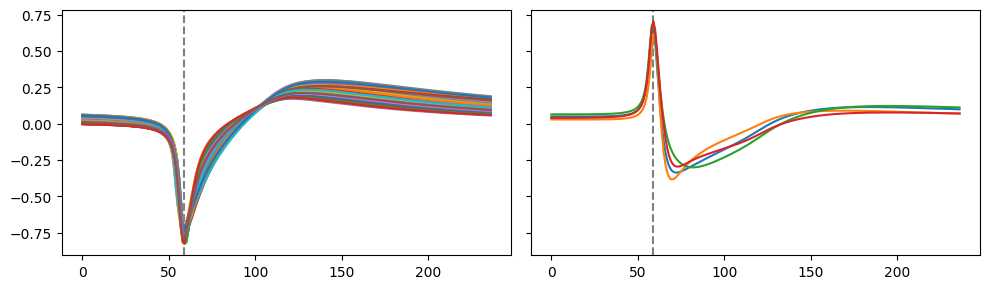

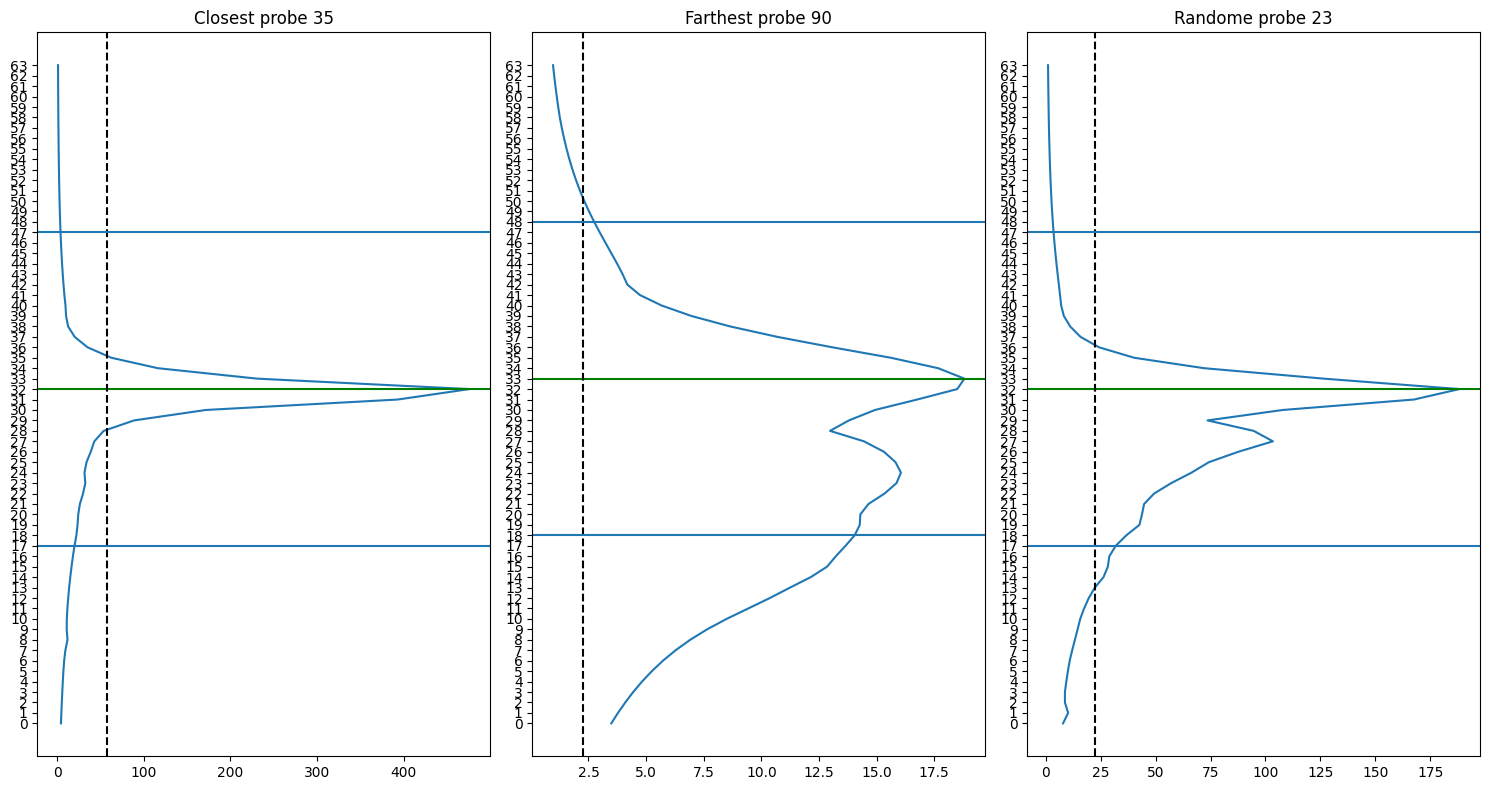

In [13]:
n_probes = 100
n_channels = 64
sim_name = 'EAP_apical_distal'
sim_flag = 'probes_dl'
num_syns = 1400

top_dir = os.path.dirname(os.path.dirname(os.getcwd()))
sim_dir = os.path.join(top_dir, f'models/NEURON/NMLCL000073-NEURON/output/{sim_name}')
# sim_label = f'{sim_name}-0nA-50Ex1-1x40Hz-{n_probes}x{n_channels}lp-{sim_flag}'  # synapses
sim_label = f'{sim_name}-0nA-{num_syns}Ex1-1x40Hz-{n_probes}x{n_channels}elec-{sim_flag}'  # current injection

eap_file_path = os.path.join(sim_dir, sim_label, f'{sim_label}-simulated_eaps.pkl')
probe_file_path = os.path.join(sim_dir, sim_label, f'{sim_label}-recording_probe_locs.pkl')

data_df = pd.read_pickle(eap_file_path)
probes = np.array(pd.read_pickle(probe_file_path))

num_probes, num_channels, _ = np.shape(probes)

probe_nums = []
channel_nums = []

for i, row in data_df.iterrows():
    probe_nums.append(int(i/num_channels))
    channel_nums.append(i%num_channels)

data_df['probe_num'] = probe_nums
data_df['channel_num'] = channel_nums

peak_threshold = 0

t = data_df.iloc[0].t
vm = data_df.iloc[0].vm
ve = data_df.iloc[0].ve

peak_time = t[np.argmin(ve)]
all_peaks = find_peaks(data_df.iloc[0].vm, threshold=peak_threshold)[0]

fig, axs = plt.subplots(1,2,figsize=(10,3),sharey=True)

offset_units = []
look_at_these = []

for probe in range(n_probes):

    probe_df = data_df[data_df['probe_num'] == probe]

    vm = probe_df.vm.iloc[0]
    t = probe_df.t.iloc[0]
    dt = t[1] - t[0]
    pre_spike_dur = 1.4
    duration = 5.6

    lb = pre_spike_dur
    ub = duration-pre_spike_dur

    all_peaks = find_peaks(vm, threshold=peak_threshold)[0]
    all_peak_times = t[all_peaks]
    for i, peak in enumerate(all_peak_times):
        if ((peak-lb) >= t[0]) and ((peak+ub) <= t[-1]):
            peak_time = peak
            peak_shift_i = all_peaks[i]
            break

    buff = 2
    start_time = peak_time - buff
    end_time = peak_time + 2*buff

    # approximate reduced timeseries condition
    t_cond = (t >= start_time) & (t < end_time)

    # find actual maximum channel
    temp_amps = []
    try:
        for _, row in probe_df.iterrows():
            wave = row.ve[t_cond]
            amp = np.max(wave) - np.min(wave)
            temp_amps.append(amp)
    except ValueError:
        raise Exception(f'ValueError: Length of Probe = {len(probe_df)} | Peak time = {peak_time}')
    
    # actual times for aligning waveform
    temp_amps = np.array(temp_amps)
    max_channel_i = np.argmax(temp_amps)

    max_channel_ve = probe_df[probe_df['channel_num']==max_channel_i].ve.iloc[0]

    # get new extracellular spike time
    peak_time_0 = peak_time
    
    min_peak = np.argmin(max_channel_ve[t_cond])
    min_peak_time = t[min_peak+peak_shift_i-int((buff/dt))]
    
    max_peak = np.argmax(max_channel_ve[t_cond])
    max_peak_time = t[max_peak+peak_shift_i-int((buff/dt))]
    
    min_diff = np.abs(peak_time_0-min_peak_time)
    max_diff = np.abs(peak_time_0-max_peak_time)

    # take whichever is more accurate
    if min_diff<max_diff:
        peak_time = min_peak_time
        peak = min_peak
        
    else:
        peak_time = max_peak_time
        peak = max_peak

    new_t_cond = (t >= peak_time - pre_spike_dur) & (t < peak_time - pre_spike_dur + duration)

    this_peak_idx = np.argwhere(t[new_t_cond] >= peak_time)[0][0]
    this_ve = max_channel_ve[new_t_cond]
    this_ve = this_ve/np.max(temp_amps)
    if this_ve[this_peak_idx]<0:
        axs[0].plot(this_ve)
    else:
        axs[1].plot(this_ve)
        
    if this_ve[20]<-0.25:       # TODO: What is this checking??
        look_at_these.append(probe)
        axs[1].plot(this_ve)
    
print('Where is spike:',this_peak_idx)
for i in range(2):
    axs[i].axvline(this_peak_idx,color='gray',linestyle='--',zorder=0)

# print('offset:',offset_units)
print('potential problems:',look_at_these)
plt.tight_layout();

closest_probe = find_n_closest_probes(probes, 1, max_channel_i=n_channels//2)
closest_probe_df = data_df[data_df.probe_num.isin(closest_probe)]

farthest_probe = find_n_farthest_probes(probes, 1, max_channel_i=n_channels//2)
farthest_probe_df = data_df[data_df.probe_num.isin(farthest_probe)]
rand_probe = np.random.choice(num_probes)
rand_probe_df = data_df[data_df.probe_num == rand_probe]

amps_close = []
amps_far = []
amps_rand = []
max_channels = []

for (_, row_close), (_, row_far), (_, row_rand) in zip(closest_probe_df.iterrows(), farthest_probe_df.iterrows(), rand_probe_df.iterrows()):

    amps_close.append(np.max(row_close.ve) - np.min(row_close.ve))
    amps_far.append(np.max(row_far.ve) - np.min(row_far.ve))
    amps_rand.append(np.max(row_rand.ve) - np.min(row_rand.ve))


fig, axs = plt.subplots(1, 3, figsize=(15,8))

for i in range(3):

    if i == 0:
        amps = amps_close
        title = f'Closest probe {closest_probe[0]}'
    elif i == 1:
        amps = amps_far
        title = f'Farthest probe {farthest_probe[0]}'
    else:
        amps = amps_rand
        title = f'Randome probe {rand_probe}'

    # axs[i].figure(figsize=(5,8))
    axs[i].plot(1e3*np.array(amps), np.arange(len(closest_probe_df)))
    axs[i].set_yticks(np.arange(len(closest_probe_df)))
    # axs[i].set_xlim((0,12))

    true_max = np.argmax(amps)
    axs[i].axhline(true_max, color='g')

    axs[i].axvline(0.12*1e3*np.max(amps), color='k', linestyle='--')

    axs[i].axhline(true_max+15)
    axs[i].axhline(true_max-15)

    axs[i].set_title(title)

    max_channels.append(true_max)
    print(true_max)

fig.tight_layout()
print(int(np.average(max_channels)))

max_channel = 32  # based on farthest and random probes
max_channels = int(np.average(max_channels))
max_channel_ve = closest_probe_df[closest_probe_df.channel_num == max_channel].ve.iloc[0]
low_channel_ve = closest_probe_df[closest_probe_df.channel_num == max_channel+15].ve.iloc[0]
t = closest_probe_df[closest_probe_df.channel_num == max_channel].t.iloc[0]

conversion_factor = 1e3
spike_duration = 5.6
start_time = peak_time - 1.6
end_time = start_time + spike_duration

t_cond = (t >= start_time) & (t < end_time)
reduced_t = t[t_cond]
reduced_max_ve = conversion_factor * max_channel_ve[t_cond]
reduced_low_ve = conversion_factor * low_channel_ve[t_cond]

T = len(reduced_t)
num_pts = 128
duration = reduced_t[-1] - reduced_t[0]
interp_t = np.linspace(0, duration, T)
cs = CubicSpline(interp_t, reduced_max_ve, axis=0)
new_time = np.linspace(0,duration,num_pts)
new_max_ve = cs(new_time)
cs = CubicSpline(interp_t,reduced_low_ve,axis=0)
new_time = np.linspace(0,duration,num_pts)
new_low_ve = cs(new_time)

farthest_probes = find_n_farthest_probes(probes, n_probes//2, max_channel_i=max_channel)
farthest_probes_df = data_df[data_df.probe_num.isin(farthest_probes)]

include_channels = [i for i in range(max_channel-15, max_channel+16)]
include_channels[0], include_channels[-1]

prep_farthest_probes_df = farthest_probes_df.copy()

probe_amps_farthest = []

for probe_num in farthest_probes:

    probe_df = farthest_probes_df[farthest_probes_df.probe_num == probe_num]

    prep_probe_df = preprocess_probe_data(probe_df, max_channel_i=max_channel, resample=512, conversion_factor=1e3, num_noisy_spikes=200)
    
    prep_farthest_probes_df.update(prep_probe_df)
    
    
    probe_amp = []

    for _, row in prep_probe_df.iterrows():

        if row.channel_num in include_channels:

            ve = row.ve
            amp = np.max(ve) - np.min(ve)
            probe_amp.append(amp)

    probe_amps_farthest.append(probe_amp)

avg_waves_far = []


for channel_num in include_channels:

    channel_df = prep_farthest_probes_df[prep_farthest_probes_df.channel_num == channel_num]

    waves = []

    for _, row in channel_df.iterrows():

        ve = row.ve
        amp = np.max(ve) - np.min(ve)
        norm_ve = np.divide(ve, amp)
        wave = list(norm_ve)
        waves.append(wave)

    waves = np.array(waves)
    channel_avg = np.average(waves, 0)

    avg_waves_far.append(channel_avg)

avg_waves_far = list(reversed(avg_waves_far))


max_channel_loc = np.argwhere(np.array(include_channels) == max_channel)[0][0]
max_avg_wave_far = avg_waves_far[max_channel_loc]

above_wave_far_apical = avg_waves_far[max_channel_loc - 6]
center_wave_far_apical = avg_waves_far[max_channel_loc]
below_wave_far_apical = avg_waves_far[max_channel_loc + 6]

## Combine

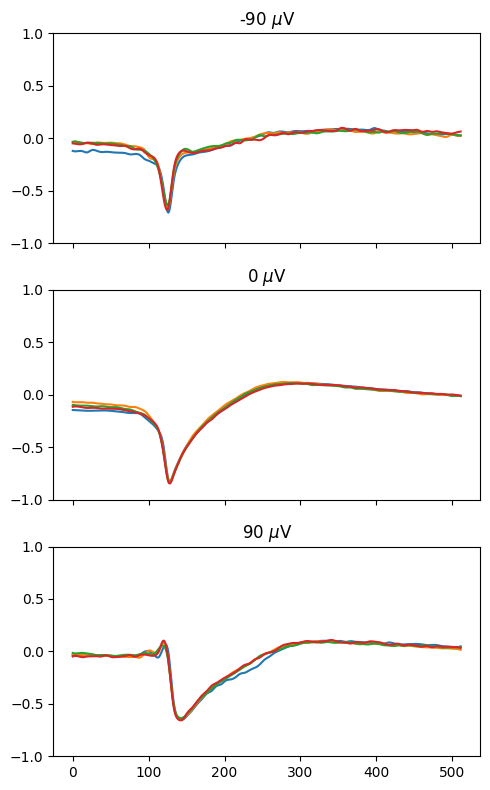

In [14]:
fig, axs = plt.subplots(3,1,figsize=(5,8), sharey=True, sharex=True)
axs = axs.ravel()

axs[0].plot(above_wave_far_current)
axs[0].plot(above_wave_far_soma)
axs[0].plot(above_wave_far_basal)
axs[0].plot(above_wave_far_apical)
axs[0].set_title(r'-90 $\mu$V')

axs[1].plot(center_wave_far_current)
axs[1].plot(center_wave_far_soma)
axs[1].plot(center_wave_far_basal)
axs[1].plot(center_wave_far_apical)
axs[1].set_title(r'0 $\mu$V')

axs[2].plot(below_wave_far_current)
axs[2].plot(below_wave_far_soma)
axs[2].plot(below_wave_far_basal)
axs[2].plot(below_wave_far_apical)
axs[2].set_title(r'90 $\mu$V')

for ax in axs:
    ax.set_ylim([-1,1])

fig.tight_layout()

# Combine

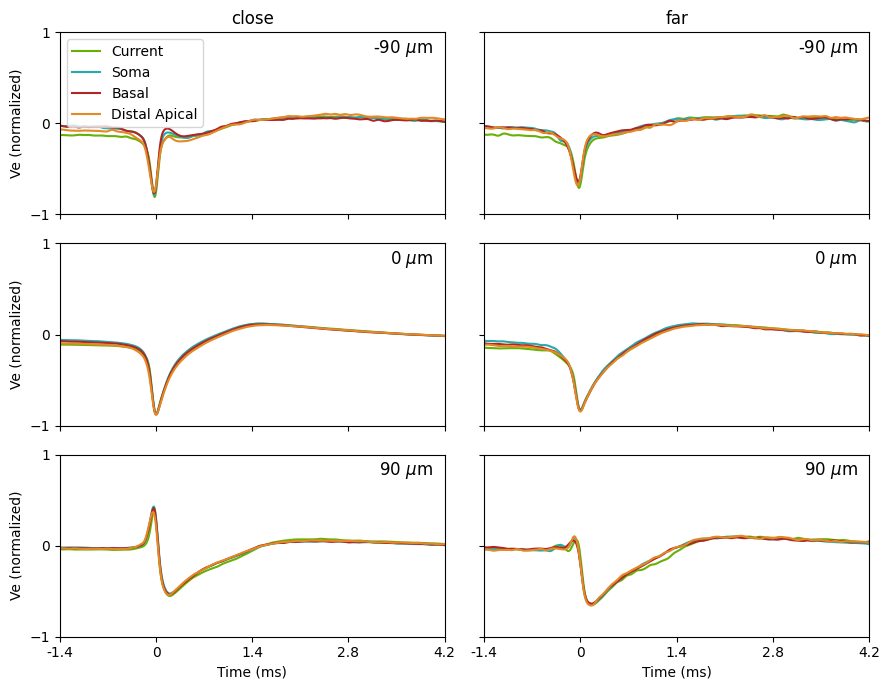

In [54]:
fig, axs = plt.subplots(3,2,figsize=(9,7), sharey=True, sharex=True)

current_waves = {'close': [above_wave_close_current, center_wave_close_current, below_wave_close_current],
                 'far': [above_wave_far_current, center_wave_far_current, below_wave_far_current]}
            
soma_waves = {'close': [above_wave_close_soma, center_wave_close_soma, below_wave_close_soma],
              'far': [above_wave_far_soma, center_wave_far_soma, below_wave_far_soma]}

basal_waves = {'close': [above_wave_close_basal, center_wave_close_basal, below_wave_close_basal],
               'far': [above_wave_far_basal, center_wave_far_basal, below_wave_far_basal]}

apical_waves = {'close': [above_wave_close_apical, center_wave_close_apical, below_wave_close_apical],
                'far': [above_wave_far_apical, center_wave_far_apical, below_wave_far_apical]}

panel_labels = [r'-90 $\mu$m', r'0 $\mu$m', r'90 $\mu$m']

in_colors = {'current': '#67B106', 'soma': '#26aaad', 'basal': '#b12625', 'apical_distal': '#e38925'}

for i, probes in enumerate(['close', 'far']):

    for j, input_type in enumerate(['above', 'center', 'below']):

        axs[j,i].plot(prep_farthest_probes_df.iloc[0].t, current_waves[probes][j], color=in_colors['current'], label='Current')
        axs[j,i].plot(prep_farthest_probes_df.iloc[0].t, soma_waves[probes][j], color=in_colors['soma'], label='Soma')
        axs[j,i].plot(prep_farthest_probes_df.iloc[0].t, basal_waves[probes][j], color=in_colors['basal'], label='Basal')
        axs[j,i].plot(prep_farthest_probes_df.iloc[0].t, apical_waves[probes][j], color=in_colors['apical_distal'], label='Distal Apical')

        axs[j,0].set_ylabel('Ve (normalized)')

        axs[j,i].text(
            0.97, 0.97,
            panel_labels[j],
            transform=axs[j,i].transAxes,
            ha='right',
            va='top',
            fontsize=12
        )

        axs[j,i].set_xticks([0, 1.4, 2.8, 4.2, 5.6])
        # axs[j,i].axvline(128)
    
    axs[0,i].set_title(probes)

    axs[-1,i].set_xticklabels([-1.4, 0, 1.4, 2.8, 4.2])
    axs[-1,i].set_xlabel('Time (ms)')

axs[0,0].set_xlim([0,5.6])
axs[0,0].legend(loc='upper left')

axs[0,0].set_ylim([-1,1])
axs[0,0].set_yticks([-1,0,1])
fig.tight_layout()
fig.savefig('channel_waveforms-close_far.png', bbox_inches='tight', dpi=300)
fig.savefig('channel_waveforms-close_far.pdf', bbox_inches='tight', dpi=300)


In [18]:
center_wave_far_apical.shape

(512,)

In [21]:
new_time.shape

(128,)

In [34]:
prep_farthest_probes_df.iloc[0].t.shape

(512,)

In [25]:
this_peak_idx

np.int64(59)

In [27]:
t[new_t_cond][59]

np.float64(1034.140380183152)